#TRABAJO PRACTICO

# Clasificación de Fisuras en Pavimento con Redes Neuronales Convolucionales,Transfer Learning y MobileNetV2

Alumno: Diego Alberto Di Stefano

Legajo: 0134844

Materia: Redes Neuronales y Deep Learning

Profesor: Alan Dreszman

Tipo de trabajo: Trabajo Práctico Integrador

Entorno de desarrollo: Google Colab - Python

Fecha de entrega: 09/10/2026

## Introducción

El objetivo de este proyecto es desarrollar un sistema de Inteligencia Artificial capaz de clasificar automáticamente diferentes tipos de fisuras en pavimentos a partir de imágenes. Esto se logrará mediante el uso de Redes Neuronales Convolucionales (CNN) y la técnica de Transfer Learning, utilizando el modelo preentrenado MobileNetV2.

### ¿Cómo ayuda este sistema a una empresa vial?

Este sistema de clasificación automática de fisuras ofrece múltiples beneficios para una empresa constructora dedicada a obras viales:

*   **Detección Temprana y Mantenimiento Predictivo:** Permite identificar y clasificar rápidamente los tipos de fisuras, facilitando la priorización y planificación del mantenimiento antes de que los daños se agraven y requieran reparaciones más costosas.
*   **Reducción de Costos:** Al automatizar el proceso de inspección, se disminuye la necesidad de mano de obra para la evaluación manual, se optimizan los recursos y se minimizan los gastos asociados a reparaciones mayores.
*   **Aumento de la Seguridad:** Una detección y reparación oportuna de las fisuras contribuye a mantener las carreteras en óptimas condiciones, mejorando la seguridad para los conductores.
*   **Consistencia y Objetividad:** El sistema proporciona una evaluación consistente y objetiva de las fisuras, eliminando la variabilidad que puede existir en las inspecciones humanas.
*   **Análisis de Datos:** La información clasificada puede ser utilizada para realizar análisis de tendencias, identificar factores que contribuyen al deterioro del pavimento y mejorar las estrategias de construcción y mantenimiento.

## Instalación de Librerías

In [10]:
# Instalar las librerías necesarias.
# Albumentations es fundamental para la aumentación de datos en tiempo real y tqdm para barras de progreso.
!pip install tensorflow keras opencv-python numpy pandas matplotlib scikit-learn albumentations tqdm pyyaml --quiet


## Librerías

In [11]:
# Importar todas las librerías que serán utilizadas en el proyecto.

import os
import shutil
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import albumentations as A
# La importación de TF_Compose de albumentations.tensorflow ya no es estándar o causa problemas.
# Usaremos albumentations con su API regular y convertiremos a tensores de TF posteriormente.
# from albumentations.tensorflow import TF_Compose


### Carga desde Google Drive

El dataset utilizado es el "Road Damage Dataset (CC0)" de Kaggle. Este dataset contiene imágenes de diferentes tipos de daños en el pavimento y sus correspondientes anotaciones en formato YOLO.

Se descargo el dataset de Kaggle y se subio a Google Drive(`road_damage_dataset.zip`)

In [12]:
import os
from google.colab import drive
drive.mount('/content/drive')

# Ruta donde se encuentra el dataset comprimido en tu Google Drive.
# Por favor, reemplaza esta ruta con la ubicación correcta de 'road_damage_dataset.zip' en tu Google Drive.
dataset_path_drive = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/DataSet/road-damage-dataset.zip'

# Directorio donde se descomprimirá el dataset
DATA_DIR = '/content/road_damage_dataset/' # Descomentado y definido aquí

# Crear el directorio si no existe
os.makedirs(DATA_DIR, exist_ok=True)

# Verificar si el archivo zip existe antes de intentar descomprimir
if not os.path.exists(dataset_path_drive):
    print(f"Error: El archivo '{dataset_path_drive}' no se encontró en Google Drive.")
    print("Por favor, asegúrate de que la ruta sea correcta y que el archivo exista.")
else:
    # Descomprimir el dataset
    print(f'Descomprimiendo dataset desde {dataset_path_drive} a {DATA_DIR}...')
    !unzip -q "{dataset_path_drive}" -d "{DATA_DIR}"
    print('Dataset descomprimido desde Google Drive.')

# Verificar el contenido del directorio descomprimido (opcional)
print(f"Contenido del directorio {DATA_DIR}:")
!ls -F {DATA_DIR}

Mounted at /content/drive
Descomprimiendo dataset desde /content/drive/MyDrive/TP_Clasificacion_Fisuras/DataSet/road-damage-dataset.zip a /content/road_damage_dataset/...
Dataset descomprimido desde Google Drive.
Contenido del directorio /content/road_damage_dataset/:
A_2890.jpeg    B_1760.txt     F_43900.txt   P_29600.jpeg  X_18510.txt
A_2890.txt     B_1870.jpeg    F_44080.jpeg  P_29600.txt   X_18520.jpeg
A_3190.jpeg    B_1870.txt     F_44080.txt   P_29670.jpeg  X_18520.txt
A_3190.txt     B_1900.jpeg    F_44130.jpeg  P_29670.txt   X_18530.jpeg
A_3200.jpeg    B_1900.txt     F_44130.txt   P_29680.jpeg  X_18530.txt
A_3200.txt     B_1970.jpeg    F_44270.jpeg  P_29680.txt   X_18540.jpeg
A_5760.jpeg    B_1970.txt     F_44270.txt   P_29690.jpeg  X_18540.txt
A_5760.txt     B_2020.jpeg    F_46970.jpeg  P_29690.txt   X_18550.jpeg
A_6180.jpeg    B_2020.txt     F_46970.txt   P_29700.jpeg  X_18550.txt
A_6180.txt     B_2050.jpeg    F_47240.jpeg  P_29700.txt   X_18560.jpeg
A_8360.jpeg    B_2050.txt 

In [13]:
import os
import shutil
import pickle

# Ruta base en Google Drive para guardar todos los artefactos
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'

# Directorios específicos dentro de Google Drive
GDRIVE_PROCESSED_DATA_DIR = os.path.join(GDRIVE_BASE_PATH, 'processed_cracks')
GDRIVE_MODELS_PATH = os.path.join(GDRIVE_BASE_PATH, 'models')
GDRIVE_HISTORY_PATH = os.path.join(GDRIVE_BASE_PATH, 'history_logs')

# Crear los directorios en Google Drive si no existen
os.makedirs(GDRIVE_PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(GDRIVE_MODELS_PATH, exist_ok=True)
os.makedirs(GDRIVE_HISTORY_PATH, exist_ok=True)

print(f"""Directorios creados en Google Drive:
- {GDRIVE_PROCESSED_DATA_DIR}
- {GDRIVE_MODELS_PATH}
- {GDRIVE_HISTORY_PATH}""")

Directorios creados en Google Drive:
- /content/drive/MyDrive/TP_Clasificacion_Fisuras/processed_cracks
- /content/drive/MyDrive/TP_Clasificacion_Fisuras/models
- /content/drive/MyDrive/TP_Clasificacion_Fisuras/history_logs


## Clases de Fisuras

El dataset original podría contener varias clases de daños.
Para este proyecto, nos enfocamos en las siguientes clases de fisuras:

*   `Longitudinal Crack`
*   `Transverse Crack`
*   `Alligator Crack`

Dejamos preparada la estructura para una futura adición de la clase `Sin fisuras` (No Crack), que podría ser útil para diferenciar imágenes sin daño de aquellas con algún tipo de fisura.


In [14]:
# Definición de las clases de fisuras que vamos a clasificar.
# Se mapean los IDs numéricos del dataset (si los hubiera) a los nombres de las clases.
# Ajustar estos mapeos según las etiquetas del dataset específico, si son diferentes.

CLASS_NAMES = { # Descomentado y definido aquí
    '0': 'Longitudinal Crack',
    '1': 'Transverse Crack',
    '2': 'Alligator Crack'
    # '3': 'Pothole', # Si el dataset original incluye otras clases, las ignoramos por ahora
    # '4': 'Patches', # o las remapeamos si es necesario.
}

# Creamos un mapeo inverso para cuando necesitemos los IDs a partir de los nombres de clase.
CLASS_NAMES_INV = {v: k for k, v in CLASS_NAMES.items()}

# Definimos las clases que serán consideradas para el modelo de clasificación.
TARGET_CLASSES = list(CLASS_NAMES.values()) # Descomentado y definido aquí
NUM_CLASSES = len(TARGET_CLASSES)

print(f"Clases objetivo para la clasificación: {TARGET_CLASSES}")
print(f"Número de clases: {NUM_CLASSES}")


Clases objetivo para la clasificación: ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack']
Número de clases: 3


## Exploración del Dataset

In [15]:
### Funciones para lectura de anotaciones YOLO
def read_yolo_annotations(image_path, annotation_dir, img_width, img_height):
    """
    Lee las anotaciones YOLO para una imagen dada.
    Args:
        image_path (str): Ruta completa de la imagen.
        annotation_dir (str): Directorio donde se encuentran los archivos .txt de anotación.
        img_width (int): Ancho de la imagen.
        img_height (int): Alto de la imagen.
    Returns:
        list: Lista de diccionarios, cada uno conteniendo 'class_id' y 'bbox' (x_min, y_min, x_max, y_max).
    """
    base_name = os.path.splitext(os.path.basename(image_path))[0]
    annotation_file = os.path.join(annotation_dir, base_name + '.txt')
    annotations = []

    if not os.path.exists(annotation_file):
        # print(f"Advertencia: Archivo de anotación no encontrado para {image_path}")
        return annotations

    with open(annotation_file, 'r') as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) == 5:
                class_id_yolo = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])

                # Convertir de formato YOLO (centro, ancho, alto normalizados) a pixeles (x_min, y_min, x_max, y_max)
                x_center_abs = x_center * img_width
                y_center_abs = y_center * img_height
                width_abs = width * img_width
                height_abs = height * img_height

                x_min = int(x_center_abs - width_abs / 2)
                y_min = int(y_center_abs - height_abs / 2)
                x_max = int(x_center_abs + width_abs / 2)
                y_max = int(y_center_abs + height_abs / 2)

                annotations.append({
                    'class_id': str(class_id_yolo),
                    'bbox': (x_min, y_min, x_max, y_max)
                })
    return annotations

def get_image_paths(data_dir):
    """
    Obtiene todas las rutas de las imágenes en el directorio de datos.
    Args:
        data_dir (str): Directorio base del dataset.
    Returns:
        list: Lista de rutas completas a las imágenes.
    """
    image_paths = []
    for root, _, files in os.walk(data_dir):
        for file in files:
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(root, file))
    return image_paths

## Conversión del Dataset

En esta sección, se implemento el script para procesar el dataset original. Esto incluye:

1.  Leer las anotaciones YOLO para cada imagen.
2.  Recortar la región de la imagen correspondiente a cada *bounding box* detectado.
3.  Guardar cada recorte en una estructura de directorios organizada por la clase de la fisura.
4.  Dividir el dataset procesado en conjuntos de entrenamiento (70%), validación (15%) y prueba (15%).

Esta preparación es esencial para el entrenamiento de un modelo de clasificación, ya que el modelo se entrenará en los recortes individuales de las fisuras, no en las imágenes completas.

In [16]:
def crop_and_save_cracks(df_annotations, output_base_dir):
    """
    Recorta las regiones de las fisuras y las guarda en carpetas de salida.
    Args:
        df_annotations (pd.DataFrame): DataFrame con las anotaciones (image_path, class_name, bbox).
        output_base_dir (str): Directorio base donde se guardarán los recortes organizados por clase.
    Returns:
        list: Lista de diccionarios con la información de cada recorte (ruta, clase, etc.).
    """
    processed_crops = []
    print(f"Iniciando recorte y guardado de fisuras en: {output_base_dir}")

    # Crear directorios para cada clase
    for class_name in TARGET_CLASSES:
        os.makedirs(os.path.join(output_base_dir, class_name), exist_ok=True)

    for idx, row in tqdm(df_annotations.iterrows(), total=len(df_annotations), desc="Recortando fisuras"):
        img_path = row['image_path']
        class_name = row['class_name']
        x_min, y_min, x_max, y_max = row['bbox']

        img = cv2.imread(img_path)
        if img is None:
            # print(f"Advertencia: No se pudo cargar la imagen para recorte: {img_path}")
            continue

        # Asegurarse de que las coordenadas del bounding box sean válidas
        h_img, w_img, _ = img.shape
        x_min = max(0, x_min)
        y_min = max(0, y_min)
        x_max = min(w_img, x_max)
        y_max = min(h_img, y_max)

        # Recortar la región
        cropped_img = img[y_min:y_max, x_min:x_max]

        if cropped_img.size == 0:
            # print(f"Advertencia: Recorte vacío para {img_path} con bbox {row['bbox']}")
            continue

        # Guardar el recorte
        output_class_dir = os.path.join(output_base_dir, class_name)
        output_filename = f"{os.path.splitext(os.path.basename(img_path))[0]}_crop_{idx}.jpg"
        output_filepath = os.path.join(output_class_dir, output_filename)

        cv2.imwrite(output_filepath, cropped_img)

        processed_crops.append({
            'image_path': output_filepath,
            'class_name': class_name
        })

    print(f"Recorte y guardado de {len(processed_crops)} fisuras completado.")
    return pd.DataFrame(processed_crops)

def split_dataset(df, train_size=0.7, val_size=0.15, test_size=0.15, random_state=42):
    """
    Divide un DataFrame en conjuntos de entrenamiento, validación y prueba, estratificando por 'class_name'.
    Args:
        df (pd.DataFrame): DataFrame con la columna 'class_name' para estratificar.
        train_size (float): Proporción para el conjunto de entrenamiento.
        val_size (float): Proporción para el conjunto de validación.
        test_size (float): Proporción para el conjunto de prueba.
        random_state (int): Semilla para la reproducibilidad.
    Returns:
        tuple: (df_train, df_val, df_test)
    """
    if not 'class_name' in df.columns:
        raise ValueError("El DataFrame debe contener la columna 'class_name' para estratificación.")

    if not np.isclose(train_size + val_size + test_size, 1.0):
        raise ValueError("Las proporciones de train, val y test deben sumar 1.")

    print(f"Dividiendo dataset con proporciones: Train={train_size*100}%, Val={val_size*100}%, Test={test_size*100}%")

    # Primero, dividir en train y el resto (val + test)
    df_train, df_temp = train_test_split(
        df, train_size=train_size, stratify=df['class_name'], random_state=random_state
    )

    # Calcular las nuevas proporciones para val y test del df_temp
    # Por ejemplo, si df_temp es 0.3 del original, y val_size es 0.15, entonces val_size_temp = 0.15 / 0.3 = 0.5
    val_ratio_of_temp = val_size / (val_size + test_size)

    df_val, df_test = train_test_split(
        df_temp, train_size=val_ratio_of_temp, stratify=df_temp['class_name'], random_state=random_state
    )

    print(f"Tamaño del conjunto de entrenamiento: {len(df_train)}")
    print(f"Tamaño del conjunto de validación: {len(df_val)}")
    print(f"Tamaño del conjunto de prueba: {len(df_test)}")

    return df_train, df_val, df_test


### Proceso de recorte y división del dataset

In [17]:
all_image_paths = get_image_paths(DATA_DIR)
print(f"Total de imágenes encontradas en el dataset: {len(all_image_paths)}")

# Recolectar estadísticas de las clases y bounding boxes
class_counts = {class_name: 0 for class_name in TARGET_CLASSES}
all_annotations = []

print("Recolectando información de anotaciones...")
for img_path in tqdm(all_image_paths, desc="Procesando imágenes"):
    img = cv2.imread(img_path)
    if img is None:
        # print(f"Error al cargar la imagen: {img_path}")
        continue

    h, w, _ = img.shape
    # El directorio de anotaciones suele estar en el mismo nivel que las imágenes o en una subcarpeta 'labels'.
    # Aquí asumimos que están en el mismo directorio que la imagen, o en un subdirectorio 'labels' si existe.
    annotation_dir_for_image = os.path.dirname(img_path)

    # Una estructura común para YOLO es /images y /labels. Vamos a intentar ambos.
    yolo_labels_root = os.path.join(DATA_DIR, 'labels') # Intentar la carpeta 'labels' en la raíz del dataset
    if os.path.exists(yolo_labels_root):
        # Ajustar la ruta del archivo de anotación para que apunte a la carpeta 'labels'
        relative_path_from_data_dir = os.path.relpath(img_path, DATA_DIR)
        label_sub_path = os.path.dirname(relative_path_from_data_dir).replace('images', '') # Eliminar 'images' si está presente
        annotation_dir_for_image = os.path.join(yolo_labels_root, label_sub_path).strip('/')
        if not annotation_dir_for_image:
            annotation_dir_for_image = yolo_labels_root # Si no hay subcarp`etas bajo 'images'

    # También verificar si la carpeta de anotaciones está al mismo nivel que la imagen
    if not os.path.exists(annotation_dir_for_image):
        annotation_dir_for_image = os.path.join(os.path.dirname(img_path).replace('images', 'labels')) # Intenta cambiar 'images' por 'labels'

    annotations = read_yolo_annotations(img_path, annotation_dir_for_image, w, h)

    for ann in annotations:
        # Solo contamos las clases que nos interesan
        if ann['class_id'] in CLASS_NAMES:
            class_name = CLASS_NAMES[ann['class_id']]
            if class_name in class_counts:
                class_counts[class_name] += 1
                all_annotations.append({
                    'image_path': img_path,
                    'class_name': class_name,
                    'bbox': ann['bbox']
                })

print("\nDistribución de clases (número de instancias de fisuras):")
for class_name, count in class_counts.items():
    print(f"- {class_name}: {count}")

# Crear un DataFrame para un manejo más fácil
df_annotations = pd.DataFrame(all_annotations)

# Directorio de salida para los recortes procesados
PROCESSED_DATA_DIR = '/content/processed_cracks/'

# Eliminar el directorio si ya existe para asegurar un inicio limpio
if os.path.exists(PROCESSED_DATA_DIR):
    shutil.rmtree(PROCESSED_DATA_DIR)
    print(f"Directorio existente {PROCESSED_DATA_DIR} eliminado.")

# Recortar y guardar las fisuras
df_cropped_data = crop_and_save_cracks(df_annotations, PROCESSED_DATA_DIR)

# Verificar si hay datos recortados antes de intentar dividir
if not df_cropped_data.empty:
    # Dividir el dataset de recortes
    df_train, df_val, df_test = split_dataset(df_cropped_data)

    print("\nDistribución de clases en el conjunto de entrenamiento:")
    print(df_train['class_name'].value_counts())

    print("\nDistribución de clases en el conjunto de validación:")
    print(df_val['class_name'].value_counts())

    print("\nDistribución de clases en el conjunto de prueba:")
    print(df_test['class_name'].value_counts())

    # Guardar los DataFrames para uso futuro (opcional, pero buena práctica)
    df_train.to_csv(os.path.join(PROCESSED_DATA_DIR, 'train_labels.csv'), index=False)
    df_val.to_csv(os.path.join(PROCESSED_DATA_DIR, 'val_labels.csv'), index=False)
    df_test.to_csv(os.path.join(PROCESSED_DATA_DIR, 'test_labels.csv'), index=False)
    print("DataFrames de entrenamiento, validación y prueba guardados.")

else:
    print("No se generaron recortes válidos. No se puede proceder con la división del dataset.")

Total de imágenes encontradas en el dataset: 3321
Recolectando información de anotaciones...


Procesando imágenes:   0%|          | 0/3321 [00:00<?, ?it/s]


Distribución de clases (número de instancias de fisuras):
- Longitudinal Crack: 2657
- Transverse Crack: 964
- Alligator Crack: 1222
Iniciando recorte y guardado de fisuras en: /content/processed_cracks/


Recortando fisuras:   0%|          | 0/4843 [00:00<?, ?it/s]

Recorte y guardado de 4843 fisuras completado.
Dividiendo dataset con proporciones: Train=70.0%, Val=15.0%, Test=15.0%
Tamaño del conjunto de entrenamiento: 3390
Tamaño del conjunto de validación: 726
Tamaño del conjunto de prueba: 727

Distribución de clases en el conjunto de entrenamiento:
class_name
Longitudinal Crack    1860
Alligator Crack        855
Transverse Crack       675
Name: count, dtype: int64

Distribución de clases en el conjunto de validación:
class_name
Longitudinal Crack    398
Alligator Crack       183
Transverse Crack      145
Name: count, dtype: int64

Distribución de clases en el conjunto de prueba:
class_name
Longitudinal Crack    399
Alligator Crack       184
Transverse Crack      144
Name: count, dtype: int64
DataFrames de entrenamiento, validación y prueba guardados.


In [18]:
import os
import shutil
import pandas # Importar pandas si se necesita para otras operaciones, aunque no para shutil.copy

# Redefinir las rutas para que esta celda sea más robusta
PROCESSED_DATA_DIR = '/content/processed_cracks/'
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'
GDRIVE_PROCESSED_DATA_DIR = os.path.join(GDRIVE_BASE_PATH, 'processed_cracks')

# Asegurar que el directorio de destino en Drive exista
os.makedirs(GDRIVE_PROCESSED_DATA_DIR, exist_ok=True)

# Lista de archivos a copiar
files_to_copy = ['train_labels.csv', 'val_labels.csv', 'test_labels.csv']
copied_any = False

print("Intentando guardar los DataFrames procesados en Google Drive...")

for filename in files_to_copy:
    local_path = os.path.join(PROCESSED_DATA_DIR, filename)
    gdrive_path = os.path.join(GDRIVE_PROCESSED_DATA_DIR, filename)

    if os.path.exists(local_path):
        try:
            shutil.copy(local_path, gdrive_path)
            print(f"'{filename}' copiado a Google Drive.")
            copied_any = True
        except Exception as e:
            print(f"Error al copiar '{filename}' a Google Drive: {e}")
    else:
        print(f"Advertencia: '{filename}' no encontrado localmente en '{PROCESSED_DATA_DIR}'. Saltando copia.")

if copied_any:
    print("Operación de copia de DataFrames a Google Drive finalizada.")
else:
    print("Ningún DataFrame fue copiado a Google Drive. Verifica que los archivos existen localmente.")

Intentando guardar los DataFrames procesados en Google Drive...
'train_labels.csv' copiado a Google Drive.
'val_labels.csv' copiado a Google Drive.
'test_labels.csv' copiado a Google Drive.
Operación de copia de DataFrames a Google Drive finalizada.


### Visualización de la distribución de clases

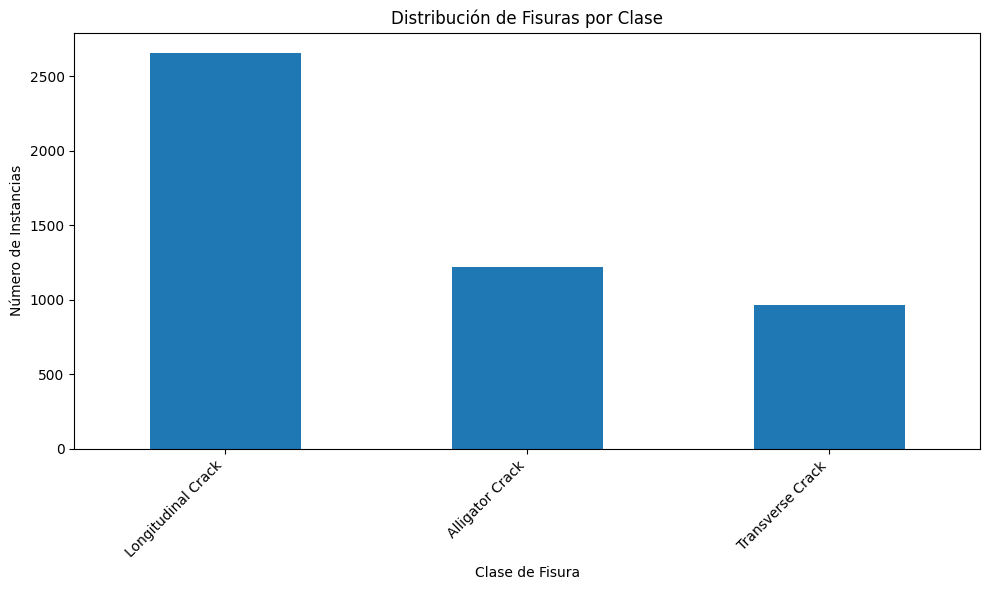

In [19]:
if 'df_annotations' in locals() and not df_annotations.empty:
    plt.figure(figsize=(10, 6))
    df_annotations['class_name'].value_counts().plot(kind='bar')
    plt.title('Distribución de Fisuras por Clase')
    plt.xlabel('Clase de Fisura')
    plt.ylabel('Número de Instancias')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron anotaciones válidas para las clases objetivo o df_annotations no está definido.\n" \
          "Por favor, verifica la estructura de tu dataset y el mapeo de CLASS_NAMES, así como la ejecución de celdas previas.")

### Ejemplos de imágenes con bounding boxes

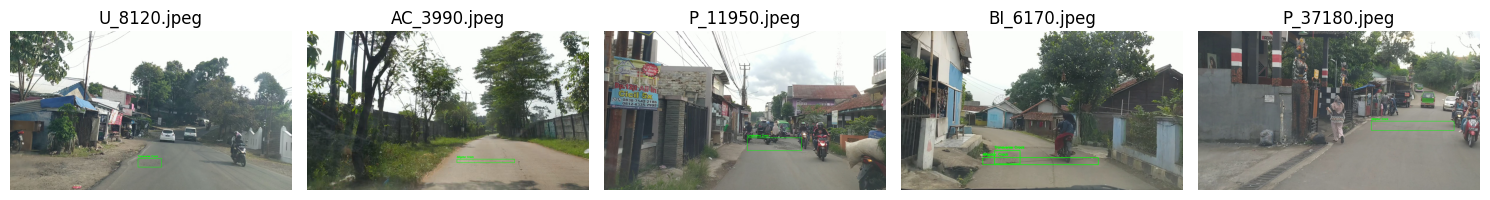

In [20]:
if not df_annotations.empty:
    # Seleccionar algunas imágenes al azar para visualización
    num_examples = 5
    unique_images = df_annotations['image_path'].unique()
    if len(unique_images) > num_examples:
        sample_images = random.sample(list(unique_images), num_examples)
    else:
        sample_images = list(unique_images)

    plt.figure(figsize=(15, 10))
    for i, img_path in enumerate(sample_images):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Obtener todas las anotaciones para esta imagen
        img_annotations = df_annotations[df_annotations['image_path'] == img_path]

        for _, row in img_annotations.iterrows():
            x_min, y_min, x_max, y_max = row['bbox']
            class_name = row['class_name']

            # Dibujar el bounding box
            cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2) # Verde
            cv2.putText(img, class_name, (x_min, y_min - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        plt.subplot(1, num_examples, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(img_path))
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No hay anotaciones para visualizar. Verifica la carga del dataset.")


### Verificación de la estructura de carpetas de recortes

In [21]:
print(f"Contenido del directorio de recortes procesados ({PROCESSED_DATA_DIR}):")
!ls -F {PROCESSED_DATA_DIR}

for class_name in TARGET_CLASSES:
    class_path = os.path.join(PROCESSED_DATA_DIR, class_name)
    if os.path.exists(class_path):
        num_files = len(os.listdir(class_path))
        print(f"  - {class_name}: {num_files} imágenes")
    else:
        print(f"  - {class_name}: Directorio no encontrado.")


Contenido del directorio de recortes procesados (/content/processed_cracks/):
'Alligator Crack'/      test_labels.csv   'Transverse Crack'/
'Longitudinal Crack'/   train_labels.csv   val_labels.csv
  - Longitudinal Crack: 2657 imágenes
  - Transverse Crack: 964 imágenes
  - Alligator Crack: 1222 imágenes


## Preprocesamiento

El preprocesamiento de imágenes es una etapa crucial para preparar los datos antes de alimentar el modelo de Machine Learning. En esta sección, realizamos las siguientes operaciones:

1.  **Redimensionamiento de imágenes:** Todas las imágenes se redimensionarán a `224x224` píxeles, un tamaño estándar para muchos modelos preentrenados como MobileNetV2.
2.  **Normalización:** Los valores de píxeles se escalarán de `[0, 255]` a `[0, 1]` para facilitar el entrenamiento de la red.
3.  **Data Augmentation (Aumento de Datos):** Utilizaremos la librería `Albumentations` para aplicar transformaciones aleatorias a las imágenes durante el entrenamiento. Esto ayuda a aumentar la cantidad y diversidad del dataset, reduciendo el sobreajuste y mejorando la capacidad de generalización del modelo. Las transformaciones incluirán rotaciones, zoom, cambios de brillo, volteo horizontal y cambios de posición (shift).

### Parámetros de preprocesamiento

In [22]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32 # Tamaño del lote para entrenamiento

print(f"Dimensiones de imágenes: {IMG_WIDTH}x{IMG_HEIGHT}")
print(f"Tamaño del lote: {BATCH_SIZE}")


Dimensiones de imágenes: 224x224
Tamaño del lote: 32


### Data Augmentation con Albumentations

In [23]:
# Definir las transformaciones de aumento de datos para el conjunto de entrenamiento.
# Albumentations ofrece una amplia gama de transformaciones de alta calidad.

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),             # Volteo horizontal aleatorio con 50% de probabilidad
    A.ShiftScaleRotate(shift_limit=0.05,  # Shift en X/Y hasta 5% del tamaño de la imagen
                       scale_limit=0.05,  # Escala hasta +/- 5%
                       rotate_limit=15,   # Rotación hasta +/- 15 grados
                       p=0.75),           # Con 75% de probabilidad
    A.RandomBrightnessContrast(brightness_limit=0.2,  # Cambios de brillo y contraste aleatorios
                               contrast_limit=0.2,
                               p=0.75),
    A.GaussNoise(p=0.2),                 # Añadir ruido gaussiano con 20% de probabilidad
    A.MotionBlur(p=0.2),                 # Desenfoque de movimiento con 20% de probabilidad
    # A.JpegCompression(quality_lower=85, quality_upper=95, p=0.2), # Simular compresión JPEG - Eliminado debido a AttributeError
    # A.RandomCrop(height=IMG_HEIGHT, width=IMG_WIDTH, p=0.5), # Crop aleatorio si se desea variar las regiones
    A.Resize(IMG_HEIGHT, IMG_WIDTH),     # Redimensionar al tamaño final
    A.Normalize(mean=(0.485, 0.456, 0.406), # Normalización con los valores medios y desviación estándar de ImageNet
                std=(0.229, 0.224, 0.225)), # Esto es común para modelos preentrenados en ImageNet
])

# Definir las transformaciones para los conjuntos de validación y prueba.
# Generalmente, solo se aplica redimensionamiento y normalización a estos conjuntos, sin aumento de datos.

val_test_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)),
])

print("Transformaciones de aumento de datos y preprocesamiento definidas.")


Transformaciones de aumento de datos y preprocesamiento definidas.


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Creación de Data Generators con TensorFlow/Keras

Utilizamos `ImageDataGenerator` de Keras, pero lo personalizaremos para que aplique las transformaciones de `Albumentations`. `flow_from_dataframe` es útil cuando las rutas de las imágenes y las etiquetas están en un DataFrame de Pandas.

In [24]:
def albumentations_transform_wrapper(image):
    """
    Envuelve la función de transformación de Albumentations para ser usada con ImageDataGenerator.
    Args:
        image (np.array): Imagen de entrada (NumPy array). ImageDataGenerator con PIL carga RGB.
    Returns:
        np.array: Imagen transformada.
    """
    # ImageDataGenerator's default image backend (PIL) loads images as RGB.
    # Albumentations expects RGB. Therefore, no BGR2RGB conversion is needed here.
    augmented_image = train_transform(image=image)['image'] # Aplicar transformación de entrenamiento
    augmented_image = augmented_image.astype(np.float32) # Asegurarse del tipo de dato correcto
    return augmented_image

def albumentations_transform_val_test_wrapper(image):
    """
    Envuelve la función de transformación de Albumentations para ser usada con ImageDataGenerator (validación/prueba).
    Args:
        image (np.array): Imagen de entrada (NumPy array). ImageDataGenerator con PIL carga RGB.
    Returns:
        np.array: Imagen transformada.
    """
    # ImageDataGenerator's default image backend (PIL) loads images as RGB.
    # Albumentations expects RGB. Therefore, no BGR2RGB conversion is needed here.
    transformed_image = val_test_transform(image=image)['image'] # Aplicar transformación de validación/prueba
    transformed_image = transformed_image.astype(np.float32)
    return transformed_image

# Crear instancias de ImageDataGenerator
# Se desactiva la normalización y otras transformaciones intrínsecas de ImageDataGenerator
# porque Albumentations ya las manejará.

train_datagen = ImageDataGenerator(
    preprocessing_function=albumentations_transform_wrapper
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=albumentations_transform_val_test_wrapper
)

# Generadores de datos a partir de los DataFrames
# Asegúrate de que 'df_train', 'df_val', 'df_test' existan del paso anterior.
# 'directory' no se usa si se pasa el camino completo en 'x_col'.

try:
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=df_train,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset=None, # Ya hemos dividido los datos
        seed=42,
        shuffle=True
    )

    validation_generator = val_test_datagen.flow_from_dataframe(
        dataframe=df_val,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset=None,
        seed=42,
        shuffle=False # No mezclar para validación
    )

    test_generator = val_test_datagen.flow_from_dataframe(
        dataframe=df_test,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        subset=None,
        seed=42,
        shuffle=False # No mezclar para prueba
    )

    print("Generadores de datos de entrenamiento, validación y prueba creados.")
    print(f"Clases detectadas por el generador: {train_generator.class_indices}")

except NameError:
    print("Error: Los DataFrames df_train, df_val, df_test no han sido definidos. " \
          "Asegúrate de ejecutar la sección 'Conversión del Dataset' primero.")
except Exception as e:
    print(f"Ocurrió un error al crear los generadores de datos: {e}")

Found 3390 validated image filenames belonging to 3 classes.
Found 726 validated image filenames belonging to 3 classes.
Found 727 validated image filenames belonging to 3 classes.
Generadores de datos de entrenamiento, validación y prueba creados.
Clases detectadas por el generador: {'Alligator Crack': 0, 'Longitudinal Crack': 1, 'Transverse Crack': 2}


### Visualización de ejemplos con Data Augmentation

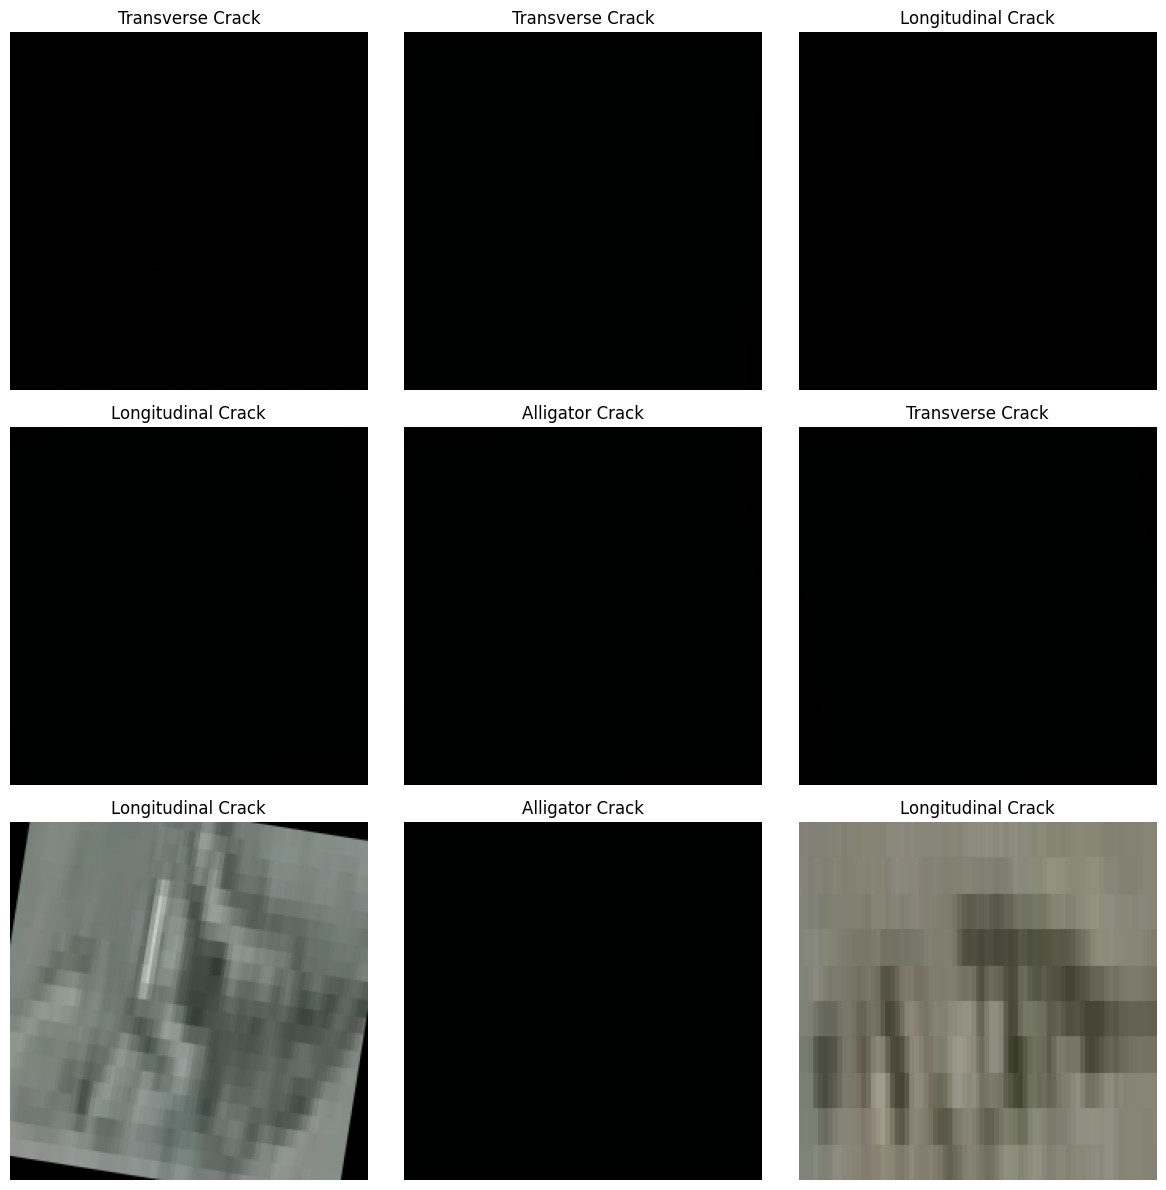

In [25]:
if 'train_generator' in locals():
    # Obtener un lote de imágenes aumentadas
    sample_images, sample_labels = next(train_generator)

    plt.figure(figsize=(12, 12))
    for i in range(min(9, len(sample_images))):
        ax = plt.subplot(3, 3, i + 1)

        # Obtener los parámetros de normalización del transformador de entrenamiento
        normalize_transform = train_transform.transforms[-1] # Assuming A.Normalize is the last transform
        # Explicitly reshape mean and std for correct broadcasting (1,1,3)
        mean = np.array(normalize_transform.mean).reshape((1, 1, 3))
        std = np.array(normalize_transform.std).reshape((1, 1, 3))
        max_pixel_value = normalize_transform.max_pixel_value # Default is 255.0

        # Desnormalizar la imagen para visualización
        img = sample_images[i] # La imagen está normalizada como (img/max_pixel_value - mean) / std
        img = (img * std + mean) * max_pixel_value # Revertir la normalización
        img = np.clip(img, 0, 255).astype(np.uint8) # Asegurarse de que los valores estén en [0, 255] y el tipo sea uint8

        plt.imshow(img) # Albumentations retorna RGB, por lo que imshow debería funcionar bien.

        # Obtener el nombre de la clase
        label_index = np.argmax(sample_labels[i])
        class_name = list(train_generator.class_indices.keys())[list(train_generator.class_indices.values()).index(label_index)]

        plt.title(class_name)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No se pudo visualizar ejemplos de aumento de datos. Asegúrate de que 'train_generator' exista.")

## Construcción del Modelo

En esta sección, construimos el modelo de clasificación utilizando Transfer Learning con la arquitectura MobileNetV2. Realizando los siguientes pasos:

1.  **Cargar MobileNetV2:** Utilizamos la versión preentrenada en ImageNet (`weights="imagenet"`) y excluiremos la capa clasificadora (`include_top=False`).
2.  **Congelar Capas Base:** Inicialmente, congelamos las capas de MobileNetV2 para que sus pesos no se modifiquen durante el primer ciclo de entrenamiento.
3.  **Añadir Capas Personalizadas:** Agregarmos capas adicionales para adaptar el modelo a nuestra tarea específica de clasificación de fisuras. Esto incluirá:
    *   `GlobalAveragePooling2D`: Para reducir las dimensiones espaciales y obtener un vector de características.
    *   Capas `Dense`: Capas completamente conectadas para aprender patrones de alto nivel.
    *   `Dropout`: Para regularización y prevención del sobreajuste.
    *   Capa `Dense` final con activación `softmax`: Para producir las probabilidades de cada clase.

In [26]:
def build_model(input_shape, num_classes):
    """
    Construye el modelo CNN utilizando MobileNetV2 preentrenado con Transfer Learning.
    Args:
        input_shape (tuple): Tupla (altura, ancho, canales) de la imagen de entrada.
        num_classes (int): Número de clases para la clasificación.
    Returns:
        tf.keras.Model: El modelo compilado listo para entrenar.
    """
    # Cargar el modelo base MobileNetV2 preentrenado en ImageNet
    # include_top=False excluye la capa clasificadora final del modelo original
    base_model = MobileNetV2(input_shape=input_shape,
                             include_top=False,
                             weights='imagenet')

    # Congelar las capas del modelo base para no reentrenar sus pesos iniciales
    base_model.trainable = False

    # Crear el modelo utilizando la API funcional de Keras
    inputs = keras.Input(shape=input_shape)
    x = base_model(inputs, training=False) # Asegurarse de que el modelo base esté en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x) # Capa de Dropout para regularización
    x = layers.Dense(128, activation='relu')(x) # Capa densa con activación ReLU
    x = layers.Dropout(0.2)(x) # Otra capa de Dropout
    outputs = layers.Dense(num_classes, activation='softmax')(x) # Capa de salida con activación softmax

    model = keras.Model(inputs, outputs)

    print("Modelo MobileNetV2 base cargado y capas añadidas.")
    model.summary()
    return model

# Definir la forma de entrada de las imágenes
input_shape = (IMG_HEIGHT, IMG_WIDTH, 3) # Altura, Ancho, Canales (RGB)

# Construir el modelo
model = build_model(input_shape, NUM_CLASSES)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Modelo MobileNetV2 base cargado y capas añadidas.


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Compilación del Modelo

Una vez definido el modelo, es necesario compilarlo especificando el optimizador, la función de pérdida y las métricas a monitorear durante el entrenamiento.

*   **Optimizador:** `Adam` es un optimizador eficiente y popular.
*   **Función de Pérdida:** `CategoricalCrossentropy` es adecuada para problemas de clasificación multiclase donde las etiquetas están en formato one-hot encoding (como las que producen `ImageDataGenerator` con `class_mode='categorical'`).
*   **Métrica:** `Accuracy` para evaluar el rendimiento de clasificación.

In [27]:
# Compilar el modelo
model.compile(optimizer=optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

print("Modelo compilado exitosamente.")


Modelo compilado exitosamente.


## Entrenamiento

En esta etapa, entrenamos el modelo utilizando los generadores de datos creados en la fase de preprocesamiento. Implementaremos varios *callbacks* de Keras para optimizar y controlar el proceso de entrenamiento:

*   **EarlyStopping:** Detendrá el entrenamiento si la métrica de validación no mejora después de un número de épocas (`patience`) para evitar el sobreajuste.
*   **ReduceLROnPlateau:** Reducirá la tasa de aprendizaje si la métrica de validación deja de mejorar, ayudando al modelo a converger a un mínimo local.
*   **ModelCheckpoint:** Guardará automáticamente el mejor modelo (basado en la métrica de validación) durante el entrenamiento.

In [28]:
# Definir la ruta para guardar el mejor modelo
CHECKPOINT_PATH = 'best_model.h5'

# Definir Callbacks
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=5, min_lr=0.000001, verbose=1),
    ModelCheckpoint(filepath=CHECKPOINT_PATH, monitor='val_accuracy', save_best_only=True, verbose=1)
]

# Definir el número de épocas
EPOCHS = 20

print("Configuraciones de entrenamiento y callbacks definidas.")


Configuraciones de entrenamiento y callbacks definidas.


### Inicio del entrenamiento

In [50]:
print(f"Iniciando el entrenamiento del modelo por {EPOCHS} épocas...")

try:
    # Entrenar el modelo
    history = model.fit(
        train_generator,
        epochs=EPOCHS,
        validation_data=validation_generator,
        callbacks=callbacks
    )

    print("Entrenamiento del modelo completado.")


except NameError:
    print("Error: Los generadores de datos no han sido definidos. " \
          "Asegúrate de ejecutar la sección 'Preprocesamiento' primero.")
except Exception as e:
    print(f"Ocurrió un error durante el entrenamiento: {e}")

Iniciando el entrenamiento del modelo por 20 épocas...
Epoch 1/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - accuracy: 0.6043 - loss: 0.9011
Epoch 1: val_accuracy did not improve from 0.88017
106/106 ━━━━━━━━━━━━━━━━━━━━ 32s 303ms/step - accuracy: 0.5965 - loss: 0.9126 - val_accuracy: 0.8719 - val_loss: 0.3516 - learning_rate: 1.0000e-06
Epoch 2/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step - accuracy: 0.5848 - loss: 0.9300
Epoch 2: val_accuracy did not improve from 0.88017
106/106 ━━━━━━━━━━━━━━━━━━━━ 31s 291ms/step - accuracy: 0.5903 - loss: 0.9267 - val_accuracy: 0.8678 - val_loss: 0.3537 - learning_rate: 1.0000e-06
Epoch 3/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.5871 - loss: 0.9322
Epoch 3: val_accuracy did not improve from 0.88017
106/106 ━━━━━━━━━━━━━━━━━━━━ 32s 298ms/step - accuracy: 0.5956 - loss: 0.9164 - val_accuracy: 0.8595 - val_loss: 0.3548 - learning_rate: 1.0000e-06
Epoch 4/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.6065 - loss: 0.8

In [48]:
import os
import shutil
import pickle

# Redefinir las rutas de Google Drive y CHECKPOINT_PATH para que esta celda sea más robusta
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'
GDRIVE_MODELS_PATH = os.path.join(GDRIVE_BASE_PATH, 'models')
GDRIVE_HISTORY_PATH = os.path.join(GDRIVE_BASE_PATH, 'history_logs')
CHECKPOINT_PATH = 'best_model.h5'

print("Guardando modelo inicial y historial de entrenamiento en Google Drive...")

# Guardar el mejor modelo inicial en Google Drive
try:
    shutil.copy(CHECKPOINT_PATH, GDRIVE_MODELS_PATH)
    print(f"Modelo '{CHECKPOINT_PATH}' guardado en Google Drive.")
except Exception as e:
    print(f"Error al guardar el modelo '{CHECKPOINT_PATH}' en Google Drive: {e}")

# Guardar el historial de entrenamiento inicial en Google Drive
try:
    with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_initial_training.pkl'), 'wb') as f:
        pickle.dump(history.history, f)
    print("Historial de entrenamiento inicial guardado en Google Drive.")
except Exception as e:
    print(f"Error al guardar el historial de entrenamiento inicial en Google Drive: {e}")

Guardando modelo inicial y historial de entrenamiento en Google Drive...
Modelo 'best_model.h5' guardado en Google Drive.
Historial de entrenamiento inicial guardado en Google Drive.


## Fine Tuning

El *Fine Tuning* es una técnica avanzada de Transfer Learning donde, después de un entrenamiento inicial con las capas base congeladas, se 'descongelan' algunas (generalmente las últimas) capas del modelo base preentrenado. Esto permite que esas capas se adapten aún más a las características específicas de nuestro nuevo dataset, mientras que las capas más bajas, que aprenden características más genéricas, permanecen congeladas o se entrenan con una tasa de aprendizaje muy pequeña. Este paso ayuda a obtener un mejor rendimiento general del modelo.

En esta sección:

1.  **Descongelaremos** las últimas capas del modelo base MobileNetV2.
2.  **Recompilaremos** el modelo con una tasa de aprendizaje mucho menor.
3.  **Entrenaremos** nuevamente el modelo por un número adicional de épocas.

In [31]:
print("Iniciando el proceso de Fine Tuning...")

# Recuperar el mejor modelo guardado durante el entrenamiento inicial
model.load_weights(CHECKPOINT_PATH)

# Descongelar el modelo base (o parte de él)
# MobileNetV2 tiene 155 capas en su base. Descongelaremos las últimas ~30 capas para permitir el fine-tuning.
base_model = model.layers[1] # La segunda capa del modelo es MobileNetV2
base_model.trainable = True

# Congelar las capas iniciales de MobileNetV2 para mantener las características de bajo nivel
for layer in base_model.layers[:-30]: # Por ejemplo, las últimas 30 capas serán entrenables
    layer.trainable = False

# Recompilar el modelo con una tasa de aprendizaje mucho menor
# Una tasa de aprendizaje pequeña es crucial para evitar 'dañar' los pesos preentrenados
model.compile(optimizer=optimizers.Adam(learning_rate=0.00001), # Tasa de aprendizaje reducida
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()
print("Modelo configurado para Fine Tuning. Capas superiores de MobileNetV2 descongeladas.")


Iniciando el proceso de Fine Tuning...


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 1,690,755 (6.45 MB)

 Non-trainable params: 731,584 (2.79 MB)

Modelo configurado para Fine Tuning. Capas superiores de MobileNetV2 descongeladas.


### Entrenamiento con Fine Tuning

In [32]:
# Definir un nuevo conjunto de Callbacks para el Fine Tuning si es necesario,
# o reutilizar los anteriores (patience puede ser diferente).
fine_tune_callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=3, min_lr=0.0000001, verbose=1),
    ModelCheckpoint(filepath='best_fine_tuned_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

FINE_TUNE_EPOCHS = 10 # Épocas adicionales para fine-tuning
TOTAL_EPOCHS = EPOCHS + FINE_TUNE_EPOCHS

print(f"Iniciando Fine Tuning por {FINE_TUNE_EPOCHS} épocas adicionales...")

try:
    history_fine_tune = model.fit(
        train_generator,
        epochs=TOTAL_EPOCHS,
        initial_epoch=history.epoch[-1], # Continuar desde la última época del entrenamiento inicial
        validation_data=validation_generator,
        callbacks=fine_tune_callbacks
    )

    print("Proceso de Fine Tuning completado.")

    # Combinar históricos para graficar después
    for metric in history.history:
        history.history[metric].extend(history_fine_tune.history[metric])

except NameError:
    print("Error: Los generadores de datos o el historial de entrenamiento inicial no han sido definidos. " \
          "Asegúrate de ejecutar las secciones anteriores primero.")
except Exception as e:
    print(f"Ocurrió un error durante el Fine Tuning: {e}")


Iniciando Fine Tuning por 10 épocas adicionales...
Epoch 20/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.5534 - loss: 1.0491
Epoch 20: val_accuracy improved from None to 0.87466, saving model to best_fine_tuned_model.h5



Epoch 20: finished saving model to best_fine_tuned_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 60s 419ms/step - accuracy: 0.5732 - loss: 0.9793 - val_accuracy: 0.8747 - val_loss: 0.3512 - learning_rate: 1.0000e-05
Epoch 21/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.5803 - loss: 0.9407
Epoch 21: val_accuracy did not improve from 0.87466
106/106 ━━━━━━━━━━━━━━━━━━━━ 31s 294ms/step - accuracy: 0.5864 - loss: 0.9404 - val_accuracy: 0.8747 - val_loss: 0.3480 - learning_rate: 1.0000e-05
Epoch 22/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step - accuracy: 0.5788 - loss: 0.9369
Epoch 22: val_accuracy did not improve from 0.87466
106/106 ━━━━━━━━━━━━━━━━━━━━ 29s 277ms/step - accuracy: 0.5873 - loss: 0.9329 - val_accuracy: 0.8691 - val_loss: 0.3491 - learning_rate: 1.0000e-05
Epoch 23/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.5865 - loss: 0.9389
Epoch 23: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.

Epoch 23: val_accuracy did not improve from 0.


Epoch 24: finished saving model to best_fine_tuned_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 30s 281ms/step - accuracy: 0.5959 - loss: 0.9101 - val_accuracy: 0.8760 - val_loss: 0.3482 - learning_rate: 5.0000e-06
Epoch 25/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.5959 - loss: 0.9128
Epoch 25: val_accuracy did not improve from 0.87603
106/106 ━━━━━━━━━━━━━━━━━━━━ 30s 279ms/step - accuracy: 0.5914 - loss: 0.9192 - val_accuracy: 0.8705 - val_loss: 0.3518 - learning_rate: 5.0000e-06
Epoch 26/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.5942 - loss: 0.9198
Epoch 26: val_accuracy did not improve from 0.87603
106/106 ━━━━━━━━━━━━━━━━━━━━ 32s 298ms/step - accuracy: 0.5891 - loss: 0.9268 - val_accuracy: 0.8705 - val_loss: 0.3536 - learning_rate: 5.0000e-06
Epoch 27/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.5937 - loss: 0.9138
Epoch 27: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.

Epoch 27: val_accuracy did not improve from 0.

In [33]:
import os
import shutil
import pickle

# Redefinir las rutas de Google Drive para que esta celda sea más robusta
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'
GDRIVE_MODELS_PATH = os.path.join(GDRIVE_BASE_PATH, 'models')
GDRIVE_HISTORY_PATH = os.path.join(GDRIVE_BASE_PATH, 'history_logs')

print("Guardando modelo fine-tuned en Google Drive...")

# Guardar el mejor modelo fine-tuned en Google Drive
try:
    shutil.copy('best_fine_tuned_model.h5', GDRIVE_MODELS_PATH)
    print("Modelo 'best_fine_tuned_model.h5' guardado en Google Drive.")
except Exception as e:
    print(f"Error al guardar el modelo 'best_fine_tuned_model.h5' en Google Drive: {e}")

# Guardar el historial combinado (inicial + fine-tuning) en Google Drive
try:
    with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_combined_fine_tuning.pkl'), 'wb') as f:
        pickle.dump(history.history, f)
    print("Historial combinado (inicial + fine-tuning) guardado en Google Drive.")
except Exception as e:
    print(f"Error al guardar el historial combinado en Google Drive: {e}")

Guardando modelo fine-tuned en Google Drive...
Modelo 'best_fine_tuned_model.h5' guardado en Google Drive.
Historial combinado (inicial + fine-tuning) guardado en Google Drive.


## Evaluación

La evaluación es una fase crítica para entender el rendimiento de nuestro modelo. Utilizamos el conjunto de datos de prueba, que el modelo no ha visto durante el entrenamiento ni el *fine tuning*, para obtener una medida imparcial de su capacidad de generalización. Calcularemos varias métricas de clasificación y visualizaremos el historial de entrenamiento.

### Cargar el mejor modelo

In [34]:
# Cargar el mejor modelo guardado durante el fine-tuning
# Si el fine-tuning no se ejecutó, se cargará el mejor modelo del entrenamiento inicial.

# Verificar si existe el modelo fine-tuned, de lo contrario cargar el inicial.
if os.path.exists('best_fine_tuned_model.h5'):
    final_model = keras.models.load_model('best_fine_tuned_model.h5')
    print("Cargado el mejor modelo después del Fine Tuning.")
elif os.path.exists(CHECKPOINT_PATH):
    final_model = keras.models.load_model(CHECKPOINT_PATH)
    print("Cargado el mejor modelo del entrenamiento inicial.")
else:
    print("Error: No se encontró ningún modelo guardado para cargar. Asegúrate de que el entrenamiento se haya completado correctamente.")
    final_model = None


Cargado el mejor modelo después del Fine Tuning.


### Evaluación en el conjunto de prueba

Evaluando el modelo en el conjunto de prueba...
23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 304ms/step - accuracy: 0.8459 - loss: 0.3844

Loss en el conjunto de prueba: 0.3844
Accuracy en el conjunto de prueba: 0.8459
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 254ms/step

--- Reporte de Clasificación ---
                    precision    recall  f1-score   support

   Alligator Crack       0.88      0.83      0.86       184
Longitudinal Crack       0.83      0.94      0.88       399
  Transverse Crack       0.87      0.61      0.72       144

          accuracy                           0.85       727
         macro avg       0.86      0.79      0.82       727
      weighted avg       0.85      0.85      0.84       727


--- Matriz de Confusión ---
[[153  28   3]
 [ 15 374  10]
 [  5  51  88]]


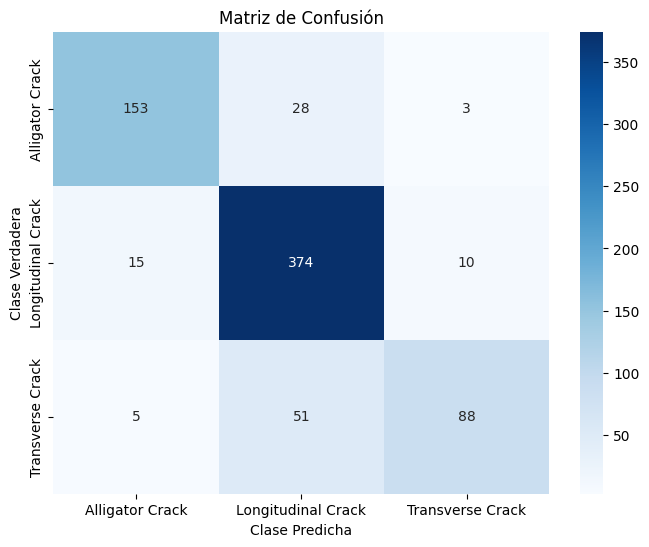

In [35]:
if final_model is not None and 'test_generator' in locals():
    print("Evaluando el modelo en el conjunto de prueba...")
    loss, accuracy = final_model.evaluate(test_generator, verbose=1)
    print(f"\nLoss en el conjunto de prueba: {loss:.4f}")
    print(f"Accuracy en el conjunto de prueba: {accuracy:.4f}")

    # Obtener predicciones para el reporte de clasificación y matriz de confusión
    test_generator.reset() # Resetear el generador para asegurar el orden
    predictions = final_model.predict(test_generator, verbose=1)
    y_pred_classes = np.argmax(predictions, axis=1)
    y_true_classes = test_generator.classes

    # Obtener nombres de las clases en el orden del generador
    class_labels = list(test_generator.class_indices.keys())

    print("\n--- Reporte de Clasificación ---")
    print(classification_report(y_true_classes, y_pred_classes, target_names=class_labels))

    print("\n--- Matriz de Confusión ---")
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    print(cm)

    # Visualizar la Matriz de Confusión
    plt.figure(figsize=(8, 6))
    import seaborn as sns
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.title('Matriz de Confusión')
    plt.xlabel('Clase Predicha')
    plt.ylabel('Clase Verdadera')
    plt.show()

else:
    print("No se pudo evaluar el modelo. Asegúrate de que el modelo y el 'test_generator' estén definidos.")


### Curvas de Accuracy y Loss durante el Entrenamiento

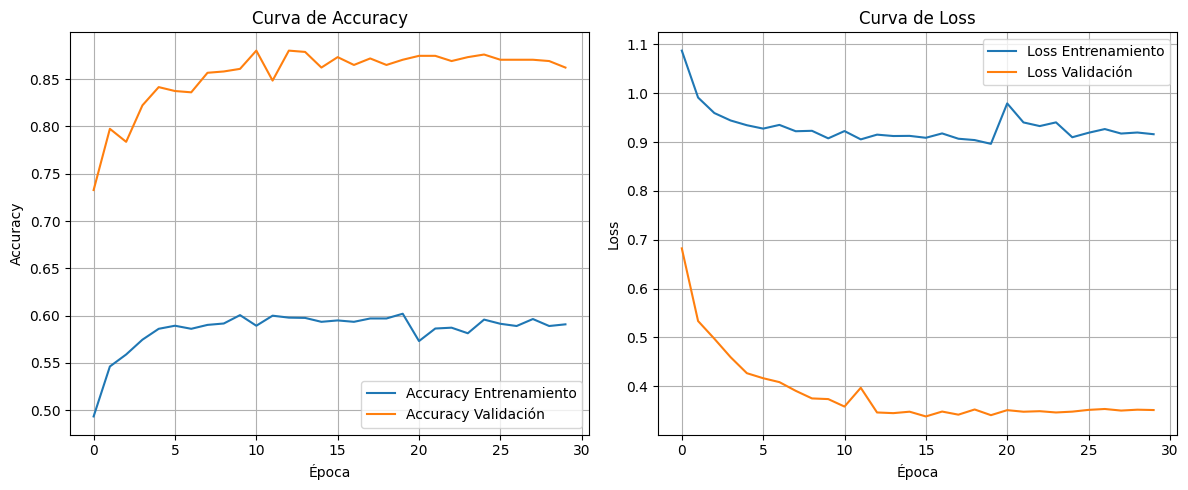

In [36]:
if 'history' in locals():
    plt.figure(figsize=(12, 5))

    # Plot de Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Accuracy Entrenamiento')
    plt.plot(history.history['val_accuracy'], label='Accuracy Validación')
    plt.title('Curva de Accuracy')
    plt.xlabel('Época')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Plot de Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Loss Entrenamiento')
    plt.plot(history.history['val_loss'], label='Loss Validación')
    plt.title('Curva de Loss')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("El historial de entrenamiento no está disponible. Asegúrate de que el entrenamiento se haya ejecutado.")


## Predicción

Finalmente, probaremos nuestro modelo entrenado con una imagen individual para simular un escenario de aplicación real. La sección de predicción permitirá:

1.  **Subir una imagen** a Google Colab.
2.  **Preprocesar** la imagen para que sea compatible con la entrada del modelo.
3.  Realizar la **predicción** de la clase de fisura.
4.  Mostrar la **imagen**, la **clase predicha**, las **probabilidades** para cada clase y el **tiempo de inferencia**.

In [37]:
from google.colab import files
import io
from PIL import Image
import time

def preprocess_image_for_prediction(image_path, target_size=(IMG_HEIGHT, IMG_WIDTH)):
    """
    Preprocesa una imagen para la predicción del modelo.
    Args:
        image_path (str): Ruta al archivo de imagen.
        target_size (tuple): Tamaño (altura, ancho) al que se redimensionará la imagen.
    Returns:
        np.array: Imagen preprocesada lista para el modelo.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"No se pudo cargar la imagen desde {image_path}")

    # Aplicar las mismas transformaciones de preprocesamiento que en validación/prueba
    # Asegúrate de que val_test_transform esté definido y contenga A.Normalize y A.Resize
    processed_img = val_test_transform(image=img)['image']

    # Expandir dimensiones para que coincida con el formato de entrada del modelo (batch_size, height, width, channels)
    return np.expand_dims(processed_img, axis=0)

def predict_single_image(model, image_path, class_labels):
    """
    Realiza una predicción sobre una única imagen.
    Args:
        model (tf.keras.Model): Modelo entrenado.
        image_path (str): Ruta al archivo de imagen a predecir.
        class_labels (list): Lista de nombres de las clases en el orden correcto.
    Returns:
        tuple: (predicted_class_name, probabilities, inference_time_ms)
    """
    try:
        # Preprocesar la imagen
        preprocessed_img = preprocess_image_for_prediction(image_path)

        # Medir tiempo de inferencia
        start_time = time.time()
        predictions = model.predict(preprocessed_img)
        end_time = time.time()
        inference_time_ms = (end_time - start_time) * 1000

        # Obtener la clase predicha y las probabilidades
        predicted_class_index = np.argmax(predictions[0])
        predicted_class_name = class_labels[predicted_class_index]
        probabilities = {class_labels[i]: f"{p:.4f}" for i, p in enumerate(predictions[0])}

        return predicted_class_name, probabilities, inference_time_ms

    except Exception as e:
        return f"Error en la predicción: {e}", {}, 0


print("Funciones de predicción definidas. Por favor, sube una imagen para probarlas.")


Funciones de predicción definidas. Por favor, sube una imagen para probarlas.


### Subir y predecir una imagen


Sube la imagen que deseas clasificar:


Saving fisura5.jfif to fisura5.jfif
Imagen 'fisura5.jfif' subida. Realizando predicción...
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


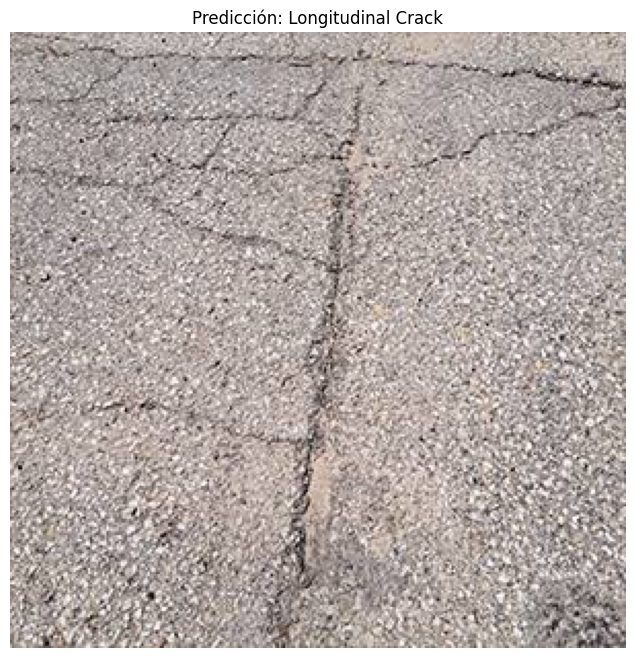


--- Resultados de Predicción para 'fisura5.jfif' ---
Clase Predicha: Longitudinal Crack
Probabilidades:
  - Alligator Crack: 0.0503
  - Longitudinal Crack: 0.5652
  - Transverse Crack: 0.3845
Tiempo de Inferencia: 4424.19 ms


In [38]:
# Cargar el modelo final entrenado (o el fine-tuned)
if 'final_model' not in locals() or final_model is None:
    if os.path.exists('best_fine_tuned_model.h5'):
        final_model = keras.models.load_model('best_fine_tuned_model.h5')
        print("Cargado el modelo final fine-tuned para predicción.")
    elif os.path.exists(CHECKPOINT_PATH):
        final_model = keras.models.load_model(CHECKPOINT_PATH)
        print("Cargado el modelo final del entrenamiento inicial para predicción.")
    else:
        print("Error: No se encontró ningún modelo guardado para predicción. Entrena el modelo primero.")

if final_model:
    # Obtener las etiquetas de clase del generador de entrenamiento
    # Asegurarse de que train_generator exista y tenga class_indices
    if 'train_generator' in locals():
        class_labels = list(train_generator.class_indices.keys())
    else:
        # Fallback si train_generator no está disponible (ej. si el cuaderno se reinició)
        class_labels = TARGET_CLASSES
        print("Advertencia: 'train_generator' no encontrado. Usando TARGET_CLASSES para etiquetas.")

    print("\nSube la imagen que deseas clasificar:")
    uploaded = files.upload()

    if uploaded:
        for fn in uploaded.keys():
            print(f"Imagen '{fn}' subida. Realizando predicción...")
            # Guardar la imagen subida temporalmente
            with open(fn, 'wb') as f:
                f.write(uploaded[fn])

            predicted_class, probabilities, inference_time = predict_single_image(final_model, fn, class_labels)

            # Mostrar la imagen original con la predicción
            img_display = cv2.imread(fn)
            img_display = cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(8, 8))
            plt.imshow(img_display)
            plt.title(f"Predicción: {predicted_class}")
            plt.axis('off')
            plt.show()

            print(f"\n--- Resultados de Predicción para '{fn}' ---")
            print(f"Clase Predicha: {predicted_class}")
            print("Probabilidades:")
            for cls, prob in probabilities.items():
                print(f"  - {cls}: {prob}")
            print(f"Tiempo de Inferencia: {inference_time:.2f} ms")

            # Eliminar la imagen temporal
            os.remove(fn)
    else:
        print("No se subió ninguna imagen.")


## Conclusiones

Este proyecto ha demostrado la viabilidad y efectividad de utilizar Redes Neuronales Convolucionales (CNN) con Transfer Learning y la arquitectura MobileNetV2 para clasificar automáticamente fisuras en pavimentos a partir de imágenes. El sistema desarrollado ofrece una solución prometedora para la gestión y mantenimiento de infraestructuras viales.

Found 3390 validated image filenames belonging to 3 classes.
Found 726 validated image filenames belonging to 3 classes.
Found 727 validated image filenames belonging to 3 classes.
Generadores de datos para la CNN desde cero creados con Albumentations mejorado.
Clases detectadas por el generador (CNN desde cero): {'Alligator Crack': 0, 'Longitudinal Crack': 1, 'Transverse Crack': 2}
Modelo CNN desde cero construido con preprocesamiento externo.


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,619 (1.62 MB)

...


Epoch 33: finished saving model to best_custom_cnn_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 30s 285ms/step - accuracy: 0.5743 - loss: 0.9579 - val_accuracy: 0.7479 - val_loss: 0.6724 - learning_rate: 1.2500e-04
Epoch 34/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.5810 - loss: 0.9489
Epoch 34: val_accuracy improved from 0.74793 to 0.79063, saving model to best_custom_cnn_model.h5



Epoch 34: finished saving model to best_custom_cnn_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 34s 323ms/step - accuracy: 0.5835 - loss: 0.9437 - val_accuracy: 0.7906 - val_loss: 0.6060 - learning_rate: 1.2500e-04
Epoch 35/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.5791 - loss: 0.9401
Epoch 35: val_accuracy did not improve from 0.79063
106/106 ━━━━━━━━━━━━━━━━━━━━ 35s 326ms/step - accuracy: 0.5737 - loss: 0.9523 - val_accuracy: 0.5675 - val_loss: 1.0955 - learning_rate: 1.2500e-04
Epoch 36/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.5760 - loss: 0.9637
Epoch 36: val_accuracy did not improve from 0.79063
106/106 ━━━━━━━━━━━━━━━━━━━━ 35s 329ms/step - accuracy: 0.5717 - loss: 0.9599 - val_accuracy: 0.5179 - val_loss: 1.0790 - learning_rate: 1.2500e-04
Epoch 37/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step - accuracy: 0.5824 - loss: 0.9460
Epoch 37: val_accuracy did not improve from 0.79063
106/106 ━━━━━━━━━━━━━━━━━━━━ 33s 309ms/step - accuracy: 0.5788 - loss: 0


Epoch 44: finished saving model to best_custom_cnn_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 33s 309ms/step - accuracy: 0.5873 - loss: 0.9315 - val_accuracy: 0.8113 - val_loss: 0.5109 - learning_rate: 6.2500e-05
Epoch 45/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.5788 - loss: 0.9444
Epoch 45: val_accuracy did not improve from 0.81129
106/106 ━━━━━━━━━━━━━━━━━━━━ 31s 292ms/step - accuracy: 0.5853 - loss: 0.9359 - val_accuracy: 0.7617 - val_loss: 0.6103 - learning_rate: 6.2500e-05
Epoch 46/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.5715 - loss: 0.9518
Epoch 46: val_accuracy improved from 0.81129 to 0.81680, saving model to best_custom_cnn_model.h5



Epoch 46: finished saving model to best_custom_cnn_model.h5
106/106 ━━━━━━━━━━━━━━━━━━━━ 34s 316ms/step - accuracy: 0.5832 - loss: 0.9434 - val_accuracy: 0.8168 - val_loss: 0.5186 - learning_rate: 6.2500e-05
Epoch 47/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.5787 - loss: 0.9377
Epoch 47: val_accuracy did not improve from 0.81680
106/106 ━━━━━━━━━━━━━━━━━━━━ 31s 295ms/step - accuracy: 0.5799 - loss: 0.9331 - val_accuracy: 0.7741 - val_loss: 0.5462 - learning_rate: 6.2500e-05
Epoch 48/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.5927 - loss: 0.9216
Epoch 48: val_accuracy did not improve from 0.81680
106/106 ━━━━━━━━━━━━━━━━━━━━ 29s 271ms/step - accuracy: 0.5832 - loss: 0.9318 - val_accuracy: 0.6198 - val_loss: 0.9158 - learning_rate: 6.2500e-05
Epoch 49/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.5833 - loss: 0.9315
Epoch 49: val_accuracy did not improve from 0.81680
106/106 ━━━━━━━━━━━━━━━━━━━━ 30s 279ms/step - accuracy: 0.5829 - loss: 0


Entrenamiento de la CNN desde cero completado.

--- Evaluación de la CNN desde cero en el conjunto de prueba ---
Modelo cargado de forma exitosa e íntegra desde el checkpoint.
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 159ms/step - accuracy: 0.7992 - loss: 0.5295

Loss en el conjunto de prueba (CNN desde cero): 0.5295
Accuracy en el conjunto de prueba (CNN desde cero): 0.7992
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 146ms/step

--- Reporte de Clasificación --- (CNN desde cero)
                    precision    recall  f1-score   support

   Alligator Crack       0.72      0.86      0.79       184
Longitudinal Crack       0.82      0.87      0.85       399
  Transverse Crack       0.87      0.51      0.65       144

          accuracy                           0.80       727
         macro avg       0.81      0.75      0.76       727
      weighted avg       0.81      0.80      0.79       727


--- Matriz de Confusión --- (CNN desde cero)
[[159  24   1]
 [ 41 348  10]
 [ 20  50  74]]


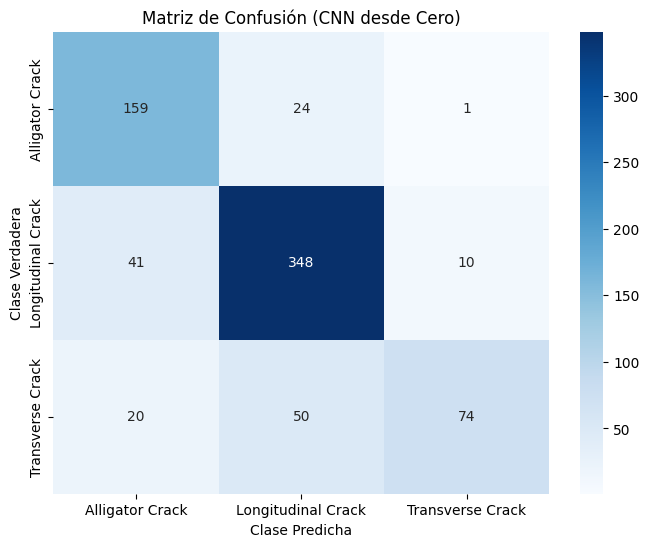

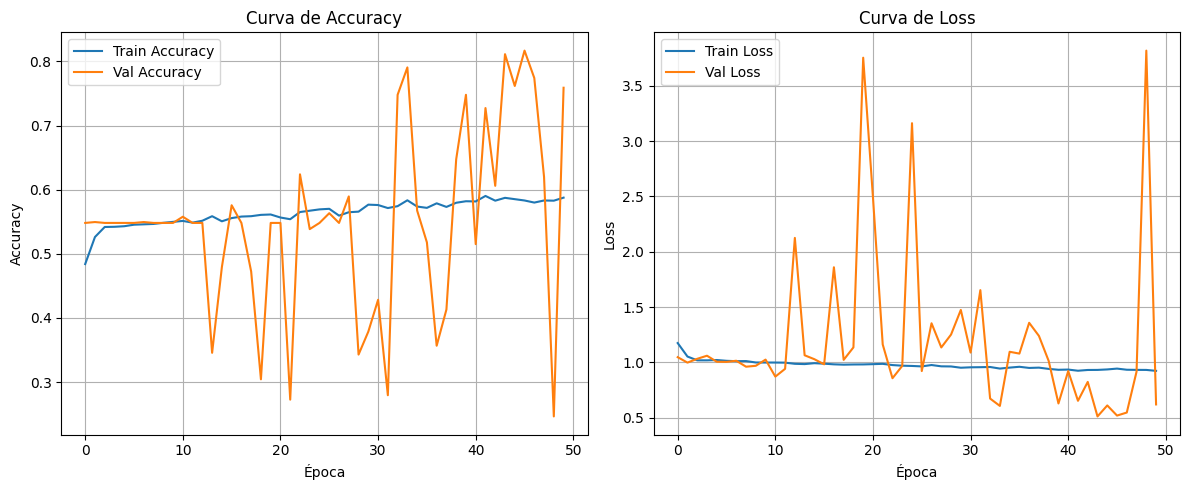

In [39]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import numpy as np
import os
import random
import albumentations as A
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Importar pandas aquí

# Re-use existing parameters from the notebook context
# Definiciones de variables necesarias re-introducidas en esta celda
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# CLASS_NAMES debe ser definido antes de TARGET_CLASSES y NUM_CLASSES
CLASS_NAMES = {
    '0': 'Longitudinal Crack',
    '1': 'Transverse Crack',
    '2': 'Alligator Crack'
}
TARGET_CLASSES = list(CLASS_NAMES.values())
NUM_CLASSES = len(TARGET_CLASSES)

# df_train, df_val, df_test deben ser DataFrames cargados o generados previamente
# Asumiendo que estos DataFrames han sido generados por la celda '40f1af12' y están disponibles en el contexto
# Si el cuaderno se reinicia, asegúrate de ejecutar las celdas '40f1af12' y '0dda8cb5' primero.
# Para una mayor robustez, se podrían cargar desde los archivos CSV guardados, pero aquí asumimos que están en memoria.

# 1. Define Albumentations transforms for custom CNN data generators
#    Incluimos augmentaciones más robustas y normalización explícita a [0, 1] aquí.

custom_cnn_train_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.HorizontalFlip(p=0.5),             # Volteo horizontal aleatorio
    A.ShiftScaleRotate(shift_limit=0.05,  # Shift, escala y rotación
                       scale_limit=0.05,
                       rotate_limit=15,
                       p=0.75),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.75), # Cambios de brillo y contraste
    A.GaussNoise(p=0.2),                 # Añadir ruido gaussiano
    A.MotionBlur(p=0.2),                 # Desenfoque de movimiento
    A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0), max_pixel_value=255.0), # Normalizar a [0, 1]
])

custom_cnn_val_test_transform = A.Compose([
    A.Resize(IMG_HEIGHT, IMG_WIDTH),
    A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0), max_pixel_value=255.0), # Normalizar a [0, 1]
])

def custom_cnn_albumentations_wrapper(image, transform):
    """
    Envuelve la transformación de Albumentations para ser usada con ImageDataGenerator.
    Aplica la transformación proporcionada (que puede incluir augmentación y normalización).
    """
    transformed_image = transform(image=image)['image']
    return transformed_image.astype(np.float32)

# 2. Create new ImageDataGenerator instances for the custom CNN
#    Ahora pasamos la función de preprocesamiento específica para cada generador.
train_datagen_cnn = ImageDataGenerator(
    preprocessing_function=lambda img: custom_cnn_albumentations_wrapper(img, custom_cnn_train_transform)
)

val_test_datagen_cnn = ImageDataGenerator(
    preprocessing_function=lambda img: custom_cnn_albumentations_wrapper(img, custom_cnn_val_test_transform)
)

try:
    # Se asume que df_train, df_val, df_test están disponibles en el entorno de ejecución.
    # Si no, se debería cargar desde los CSV previamente guardados.
    if 'df_train' not in locals() or 'df_val' not in locals() or 'df_test' not in locals():
        print("Advertencia: Los DataFrames df_train, df_val, df_test no están en el contexto actual.")
        print("Intentando cargar desde archivos CSV. Asegúrate de que las celdas previas de procesamiento se hayan ejecutado.")
        PROCESSED_DATA_DIR = '/content/processed_cracks/' # Reutilizar la ruta definida previamente

        train_csv_path = os.path.join(PROCESSED_DATA_DIR, 'train_labels.csv')
        val_csv_path = os.path.join(PROCESSED_DATA_DIR, 'val_labels.csv')
        test_csv_path = os.path.join(PROCESSED_DATA_DIR, 'test_labels.csv')

        if not os.path.exists(train_csv_path):
            raise FileNotFoundError(f"Archivo no encontrado: {train_csv_path}")
        df_train = pd.read_csv(train_csv_path)

        if not os.path.exists(val_csv_path):
            raise FileNotFoundError(f"Archivo no encontrado: {val_csv_path}")
        df_val = pd.read_csv(val_csv_path)

        if not os.path.exists(test_csv_path):
            raise FileNotFoundError(f"Archivo no encontrado: {test_csv_path}")
        df_test = pd.read_csv(test_csv_path)
        print("DataFrames cargados desde CSV.")

    train_generator_cnn = train_datagen_cnn.flow_from_dataframe(
        dataframe=df_train,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        seed=42,
        shuffle=True
    )

    validation_generator_cnn = val_test_datagen_cnn.flow_from_dataframe(
        dataframe=df_val,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        seed=42,
        shuffle=False
    )

    test_generator_cnn = val_test_datagen_cnn.flow_from_dataframe(
        dataframe=df_test,
        x_col='image_path',
        y_col='class_name',
        target_size=(IMG_HEIGHT, IMG_WIDTH),
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        seed=42,
        shuffle=False
    )
    print("Generadores de datos para la CNN desde cero creados con Albumentations mejorado.")
    print(f"Clases detectadas por el generador (CNN desde cero): {train_generator_cnn.class_indices}")

except FileNotFoundError as fnfe:
    print(f"Error: {fnfe}")
except Exception as e:
    print(f"Ocurrió un error al crear los generadores de datos para la CNN desde cero: {e}")

# 3. Define the custom CNN model
def build_custom_cnn_model(input_shape, num_classes, seed=42):
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Eliminamos layers.Rescaling y layers.Random... aquí
        # porque la normalización y aumentación ahora se hacen en los generadores de datos.

        # Conv Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 4
        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Classifier Head
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    print("Modelo CNN desde cero construido con preprocesamiento externo.")
    model.summary()
    return model

# Build the custom CNN model
input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
custom_cnn_model = build_custom_cnn_model(input_shape, NUM_CLASSES)

# 4. Compile the model
custom_cnn_model.compile(optimizer=optimizers.Adam(learning_rate=0.001),
                         loss='categorical_crossentropy',
                         metrics=['accuracy'])

print("\nModelo CNN desde cero compilado exitosamente.")

# 5. Train the model
CUSTOM_CNN_CHECKPOINT_PATH = 'best_custom_cnn_model.h5'

custom_cnn_callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=5, min_lr=0.000001, verbose=1),
    ModelCheckpoint(filepath=CUSTOM_CNN_CHECKPOINT_PATH, monitor='val_accuracy', save_best_only=True, verbose=1)
]

CUSTOM_CNN_EPOCHS = 50 # Aumentar las épocas para dar más tiempo al modelo a aprender desde cero

print(f"\nIniciando el entrenamiento de la CNN desde cero por {CUSTOM_CNN_EPOCHS} épocas...")

try:
    history_custom_cnn = custom_cnn_model.fit(
        train_generator_cnn,
        epochs=CUSTOM_CNN_EPOCHS,
        validation_data=validation_generator_cnn,
        callbacks=custom_cnn_callbacks
    )
    print("\nEntrenamiento de la CNN desde cero completado.")
except Exception as e:
    print(f"Ocurrió un error durante el entrenamiento: {e}")

# 6. Evaluate the model
print("\n--- Evaluación de la CNN desde cero en el conjunto de prueba ---")

if 'test_generator_cnn' in locals():
    if os.path.exists(CUSTOM_CNN_CHECKPOINT_PATH):
        try:
            custom_cnn_model = keras.models.load_model(CUSTOM_CNN_CHECKPOINT_PATH)
            print("Modelo cargado de forma exitosa e íntegra desde el checkpoint.")
        except Exception as load_err:
            print(f"Error al cargar modelo completo: {load_err}. Intentando cargar pesos alternativamente...")
            try:
                custom_cnn_model.load_weights(CUSTOM_CNN_CHECKPOINT_PATH)
                print("Pesos cargados sobre la arquitectura en memoria.")
            except Exception as weights_err:
                print(f"No se pudieron cargar los pesos: {weights_err}")

    loss_cnn, accuracy_cnn = custom_cnn_model.evaluate(test_generator_cnn, verbose=1)
    print(f"\nLoss en el conjunto de prueba (CNN desde cero): {loss_cnn:.4f}")
    print(f"Accuracy en el conjunto de prueba (CNN desde cero): {accuracy_cnn:.4f}")

    # Predicciones
    test_generator_cnn.reset()
    predictions_cnn = custom_cnn_model.predict(test_generator_cnn, verbose=1)
    y_pred_classes_cnn = np.argmax(predictions_cnn, axis=1)
    y_true_classes_cnn = test_generator_cnn.classes
    class_labels_cnn = list(test_generator_cnn.class_indices.keys())

    print("\n--- Reporte de Clasificación --- (CNN desde cero)")
    print(classification_report(y_true_classes_cnn, y_pred_classes_cnn, target_names=class_labels_cnn))

    print("\n--- Matriz de Confusión --- (CNN desde cero)")
    cm_cnn = confusion_matrix(y_true_classes_cnn, y_pred_classes_cnn)
    print(cm_cnn)

    # Visualizar Matriz de Confusión
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels_cnn, yticklabels=class_labels_cnn)
    plt.title('Matriz de Confusión (CNN desde Cero)')
    plt.xlabel('Clase Predicha')
    plt.ylabel('Clase Verdadera')
    plt.show()

    # Graficar Historial
    if 'history_custom_cnn' in locals():
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(history_custom_cnn.history['accuracy'], label='Train Accuracy')
        plt.plot(history_custom_cnn.history['val_accuracy'], label='Val Accuracy')
        plt.title('Curva de Accuracy')
        plt.xlabel('Época')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True)

        plt.subplot(1, 2, 2)
        plt.plot(history_custom_cnn.history['loss'], label='Train Loss')
        plt.plot(history_custom_cnn.history['val_loss'], label='Val Loss')
        plt.title('Curva de Loss')
        plt.xlabel('Época')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()
else:
    print("Generadores de prueba no disponibles para evaluación.")

In [40]:
import os
import shutil
import pickle

# Redefinir las rutas de Google Drive y CUSTOM_CNN_CHECKPOINT_PATH para que esta celda sea más robusta
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'
GDRIVE_MODELS_PATH = os.path.join(GDRIVE_BASE_PATH, 'models')
GDRIVE_HISTORY_PATH = os.path.join(GDRIVE_BASE_PATH, 'history_logs')
CUSTOM_CNN_CHECKPOINT_PATH = 'best_custom_cnn_model.h5'

print("Guardando modelo CNN desde cero y historial en Google Drive...")

# Guardar el mejor modelo CNN desde cero en Google Drive
try:
    shutil.copy(CUSTOM_CNN_CHECKPOINT_PATH, GDRIVE_MODELS_PATH)
    print(f"Modelo '{CUSTOM_CNN_CHECKPOINT_PATH}' guardado en Google Drive.")
except Exception as e:
    print(f"Error al guardar el modelo '{CUSTOM_CNN_CHECKPOINT_PATH}' en Google Drive: {e}")

# Guardar el historial de entrenamiento de la CNN desde cero en Google Drive
if 'history_custom_cnn' in locals():
    try:
        with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_custom_cnn.pkl'), 'wb') as f:
            pickle.dump(history_custom_cnn.history, f)
        print("Historial de entrenamiento de la CNN desde cero guardado en Google Drive.")
    except Exception as e:
        print(f"Error al guardar el historial de la CNN desde cero en Google Drive: {e}")
else:
    print("Advertencia: 'history_custom_cnn' no encontrado. No se guardará el historial de la CNN desde cero.")

Guardando modelo CNN desde cero y historial en Google Drive...
Modelo 'best_custom_cnn_model.h5' guardado en Google Drive.
Historial de entrenamiento de la CNN desde cero guardado en Google Drive.


Directorios de resultados de comparación creados:
- Local: /content/comparison_results/
- Google Drive: /content/drive/MyDrive/TP_Clasificacion_Fisuras/comparison_results
Cargando historial de MobileNetV2 (entrenamiento inicial) desde Google Drive...
Generando gráficos de curvas de entrenamiento...


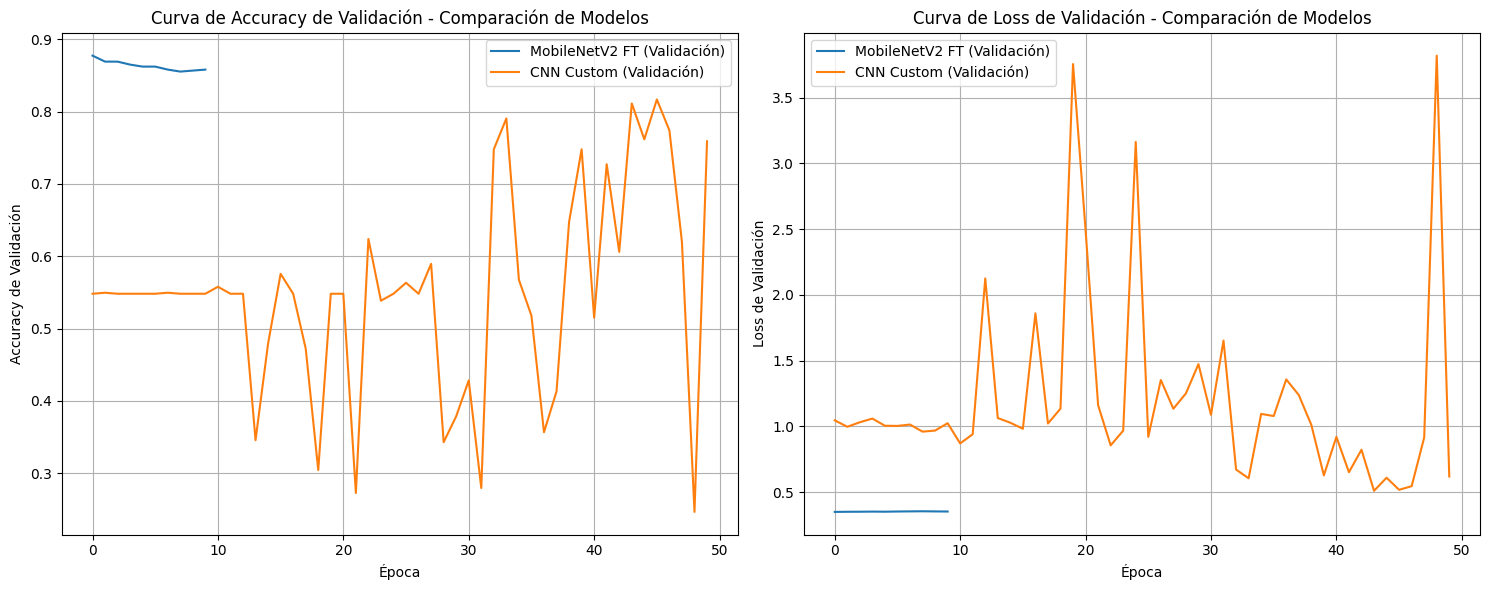

Gráficos de curvas de validación guardados localmente.
Generando resumen tabular de métricas finales...


Modelo MobileNetV2 Base cargado de: best_model.h5
Evaluación de MobileNetV2 Base: Loss=0.3987, Accuracy=0.8473

--- Resumen de Métricas Finales en Conjunto de Prueba ---
                      Modelo  Test Loss  Test Accuracy
MobileNetV2 Base (Congelado)   0.398720       0.847318
 MobileNetV2 con Fine-Tuning   0.384441       0.845942
       CNN Custom desde Cero   0.529522       0.799175
Resumen de métricas guardado localmente en: /content/comparison_results/comparison_summary.csv


/tmp/ipykernel_1826/2275545534.py:195: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='Test Accuracy', data=df_comparison, palette='viridis')
/tmp/ipykernel_1826/2275545534.py:202: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Modelo', y='Test Loss', data=df_comparison, palette='magma')


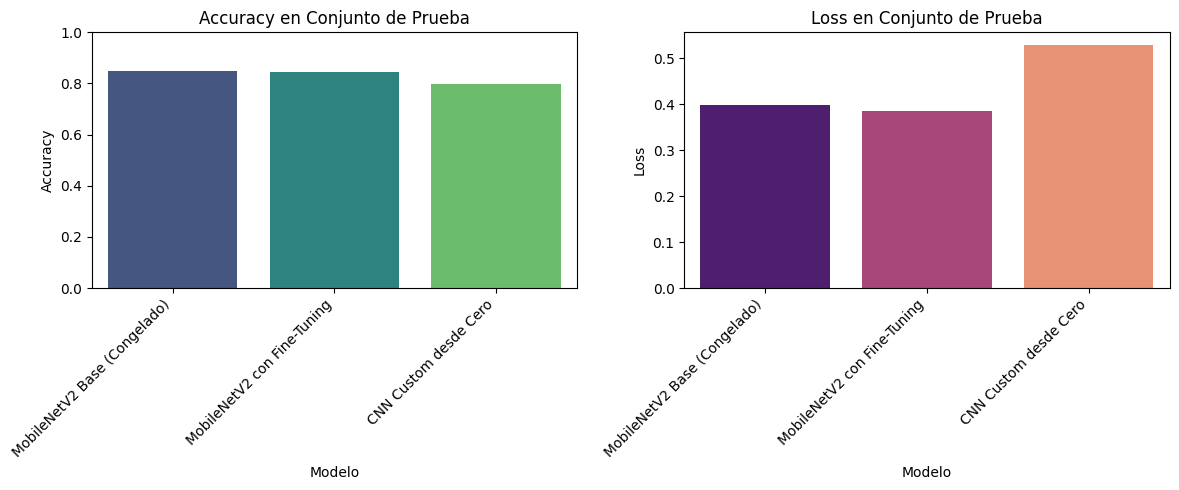

Gráfico de métricas de prueba guardado localmente.

Copiando resultados a Google Drive...
Resultados copiados exitosamente a Google Drive.


In [49]:
import os
import shutil
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf # Importar TensorFlow para cargar modelos

# --- 1. Definir rutas de guardado --- Local y Google Drive ---
LOCAL_COMPARISON_DIR = '/content/comparison_results/'
# GDRIVE_HISTORY_PATH ya está definido, pero lo redefinimos para robustez en esta celda
GDRIVE_BASE_PATH = '/content/drive/MyDrive/TP_Clasificacion_Fisuras/'
GDRIVE_COMPARISON_DIR = os.path.join(GDRIVE_BASE_PATH, 'comparison_results')

os.makedirs(LOCAL_COMPARISON_DIR, exist_ok=True)
os.makedirs(GDRIVE_COMPARISON_DIR, exist_ok=True)
print(f"Directorios de resultados de comparación creados:")
print(f"- Local: {LOCAL_COMPARISON_DIR}")
print(f"- Google Drive: {GDRIVE_COMPARISON_DIR}")

# --- 2. Cargar historiales de entrenamiento (si no están en memoria) ---
# Asegurarse de que GDRIVE_HISTORY_PATH esté disponible, ya está definido en el kernel.

# MobileNetV2 History (combinado inicial + fine-tuning) se espera que esté en 'history'
if 'history' not in locals():
    print("Cargando historial de MobileNetV2 (con fine-tuning) desde Google Drive...")
    try:
        with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_combined_fine_tuning.pkl'), 'rb') as f:
            history_mnv2_combined = pickle.load(f)
    except FileNotFoundError:
        print("Error: 'history_combined_fine_tuning.pkl' no encontrado. Asegúrate de ejecutar el entrenamiento de MobileNetV2 y guardarlo.")
        history_mnv2_combined = None
    except Exception as e:
        print(f"Error al cargar history_combined_fine_tuning.pkl: {e}")
else:
    history_mnv2_combined = history.history

# MobileNetV2 History (solo entrenamiento inicial) - NUEVO
history_mnv2_initial = None # Inicializar para evitar NameError si no se carga
initial_epochs = EPOCHS # Asumiendo que EPOCHS está definido en una celda previa para el entrenamiento inicial.

print("Cargando historial de MobileNetV2 (entrenamiento inicial) desde Google Drive...")
try:
    with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_initial_training.pkl'), 'rb') as f:
        loaded_initial_history = pickle.load(f)

    # Verificar si el historial cargado contiene las métricas de validación necesarias
    if 'val_accuracy' in loaded_initial_history and 'val_loss' in loaded_initial_history:
        history_mnv2_initial = loaded_initial_history
    else:
        print("Advertencia: El historial de entrenamiento inicial cargado no contiene métricas de validación.")
        # Si el historial combinado está disponible, extraer la parte inicial de este.
        if history_mnv2_combined and 'val_accuracy' in history_mnv2_combined and 'val_loss' in history_mnv2_combined:
            print(f"Intentando extraer las primeras {initial_epochs} épocas del historial combinado para MobileNetV2 Base.")
            history_mnv2_initial = {
                'val_accuracy': history_mnv2_combined['val_accuracy'][:initial_epochs],
                'val_loss': history_mnv2_combined['val_loss'][:initial_epochs]
            }
            # Asegurarse de que la longitud coincida
            if len(history_mnv2_initial['val_accuracy']) != initial_epochs:
                 print(f"Advertencia: Longitud del historial inicial extraído ({len(history_mnv2_initial['val_accuracy'])}) no coincide con EPOCHS ({initial_epochs}).")

except FileNotFoundError:
    print("Advertencia: 'history_initial_training.pkl' no encontrado.")
    # Si el archivo no se encuentra, intentar derivar del historial combinado si está disponible
    if history_mnv2_combined and 'val_accuracy' in history_mnv2_combined and 'val_loss' in history_mnv2_combined:
        print(f"Derivando historial inicial desde el historial combinado (primeras {initial_epochs} épocas).")
        history_mnv2_initial = {
            'val_accuracy': history_mnv2_combined['val_accuracy'][:initial_epochs],
            'val_loss': history_mnv2_combined['val_loss'][:initial_epochs]
        }
        if len(history_mnv2_initial['val_accuracy']) != initial_epochs:
            print(f"Advertencia: Longitud del historial inicial derivado ({len(history_mnv2_initial['val_accuracy'])}) no coincide con EPOCHS ({initial_epochs}).")

except Exception as e:
    print(f"Error al cargar history_initial_training.pkl: {e}")

# Custom CNN History se espera que esté en 'history_custom_cnn'
if 'history_custom_cnn' not in locals():
    print("Cargando historial de CNN personalizada desde Google Drive...")
    try:
        with open(os.path.join(GDRIVE_HISTORY_PATH, 'history_custom_cnn.pkl'), 'rb') as f:
            history_custom_cnn_data = pickle.load(f)
    except FileNotFoundError:
        print("Error: 'history_custom_cnn.pkl' no encontrado. Asegúrate de ejecutar el entrenamiento de la CNN personalizada y guardarlo.")
        history_custom_cnn_data = None
    except Exception as e:
        print(f"Error al cargar history_custom_cnn.pkl: {e}")
else:
    history_custom_cnn_data = history_custom_cnn.history

# --- 3. Generar gráficos comparativos de curvas de Accuracy y Loss ---
print("Generando gráficos de curvas de entrenamiento...")
plt.figure(figsize=(15, 6))

# Plot de Accuracy
plt.subplot(1, 2, 1)
# if history_mnv2_initial:
#     plt.plot(history_mnv2_initial['val_accuracy'], label='MobileNetV2 Base (Validación)')
if history_mnv2_combined:
    plt.plot(history_mnv2_combined['val_accuracy'], label='MobileNetV2 FT (Validación)')
if history_custom_cnn_data:
    plt.plot(history_custom_cnn_data['val_accuracy'], label='CNN Custom (Validación)')
plt.title('Curva de Accuracy de Validación - Comparación de Modelos')
plt.xlabel('Época')
plt.ylabel('Accuracy de Validación')
plt.legend()
plt.grid(True)

# Plot de Loss
plt.subplot(1, 2, 2)
# if history_mnv2_initial:
#     plt.plot(history_mnv2_initial['val_loss'], label='MobileNetV2 Base (Validación)')
if history_mnv2_combined:
    plt.plot(history_mnv2_combined['val_loss'], label='MobileNetV2 FT (Validación)')
if history_custom_cnn_data:
    plt.plot(history_custom_cnn_data['val_loss'], label='CNN Custom (Validación)')
plt.title('Curva de Loss de Validación - Comparación de Modelos')
plt.xlabel('Época')
plt.ylabel('Loss de Validación')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(LOCAL_COMPARISON_DIR, 'comparison_curves_val_only.png')) # Cambiado el nombre del archivo
plt.show()
print("Gráficos de curvas de validación guardados localmente.")

# --- 4. Resumen tabular de métricas finales en el conjunto de prueba ---
print("Generando resumen tabular de métricas finales...")

# Cargar el modelo MobileNetV2 Base (antes del fine-tuning) y evaluarlo
initial_mnv2_model = None
initial_loss = None
initial_accuracy = None

# CHECKPOINT_PATH se define en celdas previas, se asume su disponibilidad.
# Si no está en el contexto, se podría definir aquí: CHECKPOINT_PATH = 'best_model.h5'
if 'CHECKPOINT_PATH' not in locals():
    CHECKPOINT_PATH = 'best_model.h5'

if os.path.exists(CHECKPOINT_PATH) and 'test_generator' in locals():
    try:
        initial_mnv2_model = tf.keras.models.load_model(CHECKPOINT_PATH)
        print(f"Modelo MobileNetV2 Base cargado de: {CHECKPOINT_PATH}")
        # Asegurarse de que test_generator esté listo para usar
        test_generator.reset()
        initial_loss, initial_accuracy = initial_mnv2_model.evaluate(test_generator, verbose=0)
        print(f"Evaluación de MobileNetV2 Base: Loss={initial_loss:.4f}, Accuracy={initial_accuracy:.4f}")
    except Exception as e:
        print(f"Error al cargar o evaluar MobileNetV2 Base: {e}")
else:
    print(f"Advertencia: Modelo inicial '{CHECKPOINT_PATH}' no encontrado o 'test_generator' no disponible. No se incluirá en la comparativa de métricas de prueba.")

results_data = []

# Agregar MobileNetV2 Base si se cargó y evaluó
if initial_loss is not None and initial_accuracy is not None:
    results_data.append({
        'Modelo': 'MobileNetV2 Base (Congelado)',
        'Test Loss': initial_loss,
        'Test Accuracy': initial_accuracy
    })

# Agregar MobileNetV2 con Fine-Tuning y CNN Custom (asumiendo que 'loss', 'accuracy', 'loss_cnn', 'accuracy_cnn' están en el contexto)
# Se deben asegurar que estas variables existan del contexto previo.
if 'loss' in locals() and 'accuracy' in locals():
    results_data.append({
        'Modelo': 'MobileNetV2 con Fine-Tuning',
        'Test Loss': loss,
        'Test Accuracy': accuracy
    })

if 'loss_cnn' in locals() and 'accuracy_cnn' in locals():
    results_data.append({
        'Modelo': 'CNN Custom desde Cero',
        'Test Loss': loss_cnn,
        'Test Accuracy': accuracy_cnn
    })

df_comparison = pd.DataFrame(results_data)

print("\n--- Resumen de Métricas Finales en Conjunto de Prueba ---")
print(df_comparison.to_string(index=False))

# Guardar el resumen localmente como CSV y también mostrarlo
csv_path_local = os.path.join(LOCAL_COMPARISON_DIR, 'comparison_summary.csv')
df_comparison.to_csv(csv_path_local, index=False)
print(f"Resumen de métricas guardado localmente en: {csv_path_local}")

# --- 5. Graficar comparación de Accuracy y Loss en test ---
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(x='Modelo', y='Test Accuracy', data=df_comparison, palette='viridis')
plt.title('Accuracy en Conjunto de Prueba')
plt.ylim(0, 1) # Accuracy va de 0 a 1
plt.ylabel('Accuracy')
plt.xticks(rotation=45, ha='right') # Mejorar legibilidad de etiquetas

plt.subplot(1, 2, 2)
sns.barplot(x='Modelo', y='Test Loss', data=df_comparison, palette='magma')
plt.title('Loss en Conjunto de Prueba')
plt.ylabel('Loss')
plt.xticks(rotation=45, ha='right') # Mejorar legibilidad de etiquetas

plt.tight_layout()
plt.savefig(os.path.join(LOCAL_COMPARISON_DIR, 'comparison_test_metrics.png'))
plt.show()
print("Gráfico de métricas de prueba guardado localmente.")

# --- 6. Copiar resultados a Google Drive ---
print("\nCopiando resultados a Google Drive...")
try:
    # Copiar gráficos
    shutil.copy(os.path.join(LOCAL_COMPARISON_DIR, 'comparison_curves_val_only.png'), GDRIVE_COMPARISON_DIR) # Nombre de archivo actualizado
    shutil.copy(os.path.join(LOCAL_COMPARISON_DIR, 'comparison_test_metrics.png'), GDRIVE_COMPARISON_DIR)
    # Copiar CSV
    shutil.copy(csv_path_local, GDRIVE_COMPARISON_DIR)
    print("Resultados copiados exitosamente a Google Drive.")
except Exception as e:
    print(f"Error al copiar resultados a Google Drive: {e}")